# Semana 7 Modelo UML estados y preparación EVI1

Documentar el proyecto del hotel mediante clases, dos secuencias y estados, comprobar su correspondencia con el código y preparar el paquete técnico EVI1.

Identificador S7-001. Completar ApellidoNombre antes de entregar. Solución elaborada con asistencia de IA. No equivale a una sustentación realizada.


## Preparar archivos

Las celdas writefile guardan las fuentes visibles en el entorno de Colab. Ejecutarlas en orden. Se requiere Python 3.12 o superior y g++ con C++17.


In [ ]:
from pathlib import Path
for carpeta in ["python", "cpp", "tests", ".build", "evidencias"]:
    Path(carpeta).mkdir(exist_ok=True)


### python\__init__.py

In [ ]:
%%writefile python/__init__.py


### python\errores_hotel.py

In [ ]:
%%writefile python/errores_hotel.py
"""Errores del dominio hotelero y verificadores de contratos."""


class ErrorHotel(Exception):
    pass


class ErrorDatosHotel(ErrorHotel):
    pass


class ErrorEstadoReserva(ErrorHotel):
    pass


class ErrorDisponibilidad(ErrorHotel):
    pass


### python\estados.py

In [ ]:
%%writefile python/estados.py
"""Máquinas de estados con validación previa a cualquier mutación."""

from enum import Enum, auto


class EstadoMatricula(Enum):
    REGISTRADA = auto()
    VIGENTE = auto()
    SUSPENDIDA = auto()
    ANULADA = auto()


class MaquinaEstados:
    def __init__(self, inicial, transiciones):
        self._estado = inicial
        self._TRANSICIONES = dict(transiciones)
        self._historial = [(None, inicial)]

    @property
    def estado(self):
        return self._estado

    @property
    def historial(self):
        return tuple(self._historial)

    def transicionar(self, destino, contexto=None):
        clave = (self._estado, destino)
        if clave not in self._TRANSICIONES:
            raise ValueError("Transicion no permitida")
        guardia = self._TRANSICIONES[clave]
        if guardia and not guardia(contexto or {}):
            raise ValueError("Guardia no satisfecha")
        self._historial.append((self._estado, destino))
        self._estado = destino


class Matricula:
    def __init__(self, codigo="E001", cursos=("SIS206",)):
        if not codigo.strip() or not 1 <= len(cursos) <= 6 or len(set(cursos)) != len(cursos):
            raise ValueError("Matricula invalida")
        self._codigo, self._cursos = codigo, tuple(cursos)
        E = EstadoMatricula
        self._maquina = MaquinaEstados(
            E.REGISTRADA,
            {
                (E.REGISTRADA, E.VIGENTE): None,
                (E.REGISTRADA, E.ANULADA): None,
                (E.VIGENTE, E.SUSPENDIDA): None,
                (E.VIGENTE, E.ANULADA): None,
                (E.SUSPENDIDA, E.VIGENTE): None,
                (E.SUSPENDIDA, E.ANULADA): None,
            },
        )
        self._motivo = ""

    @property
    def estado(self):
        return self._maquina.estado

    @property
    def historial(self):
        return self._maquina.historial

    @property
    def motivo(self):
        return self._motivo

    def validar_pago(self):
        if self.estado != EstadoMatricula.REGISTRADA:
            raise ValueError("Pago solo desde registrada")
        self._maquina.transicionar(EstadoMatricula.VIGENTE)

    def suspender(self, motivo):
        if not motivo.strip():
            raise ValueError("Motivo requerido")
        self._maquina.transicionar(EstadoMatricula.SUSPENDIDA)
        self._motivo = motivo

    def regularizar(self):
        if self.estado != EstadoMatricula.SUSPENDIDA:
            raise ValueError("Regularizar solo suspendida")
        self._maquina.transicionar(EstadoMatricula.VIGENTE)
        self._motivo = ""

    def anular(self):
        self._maquina.transicionar(EstadoMatricula.ANULADA)


class EstadoReserva(Enum):
    REGISTRADA = auto()
    CONFIRMADA = auto()
    HOSPEDADA = auto()
    FINALIZADA = auto()
    ANULADA = auto()


def maquina_reserva():
    E = EstadoReserva
    return MaquinaEstados(
        E.REGISTRADA,
        {
            (E.REGISTRADA, E.CONFIRMADA): None,
            (E.REGISTRADA, E.ANULADA): None,
            (E.CONFIRMADA, E.HOSPEDADA): None,
            (E.CONFIRMADA, E.ANULADA): None,
            (E.HOSPEDADA, E.FINALIZADA): None,
        },
    )


### python\hotel_base.py

In [ ]:
%%writefile python/hotel_base.py
"""Modelo inicial del proyecto hotelero correspondiente a la semana 2."""

from datetime import date
from math import isfinite


def texto(valor):
    if not isinstance(valor, str) or not valor.strip():
        raise ValueError("Texto no vacio requerido")
    return valor


def entero(valor, minimo, maximo):
    if type(valor) is not int or not minimo <= valor <= maximo:
        raise ValueError("Entero fuera de rango")
    return valor


class Huesped:
    def __init__(self, identificador, nombre, documento):
        self.__id = texto(identificador)
        self.nombre = nombre
        self.documento = documento

    @property
    def id(self):
        return self.__id

    @property
    def nombre(self):
        return self.__nombre

    @nombre.setter
    def nombre(self, valor):
        self.__nombre = texto(valor)

    @property
    def documento(self):
        return self.__documento

    @documento.setter
    def documento(self, valor):
        if (
            not isinstance(valor, str)
            or len(valor) != 8
            or not valor.isascii()
            or not valor.isdigit()
        ):
            raise ValueError("DNI debe tener ocho digitos ASCII")
        self.__documento = valor

    @property
    def etiqueta(self):
        return f"{self.id} {self.nombre}"

    def actualizar_documento(self, documento):
        self.documento = documento


class Habitacion:
    def __init__(self, numero, tipo, capacidad, tarifa):
        self.__numero = entero(numero, 1, 9999)
        self.__ocupantes = 0
        self.tipo = tipo
        self.capacidad = capacidad
        self.tarifa = tarifa

    @property
    def numero(self):
        return self.__numero

    @property
    def tipo(self):
        return self.__tipo

    @tipo.setter
    def tipo(self, valor):
        self.__tipo = texto(valor)

    @property
    def capacidad(self):
        return self.__capacidad

    @capacidad.setter
    def capacidad(self, valor):
        entero(valor, 1, 10)
        if valor < self.__ocupantes:
            raise ValueError("Capacidad menor que ocupantes")
        self.__capacidad = valor

    @property
    def tarifa(self):
        return self.__tarifa

    @tarifa.setter
    def tarifa(self, valor):
        if (
            isinstance(valor, bool)
            or not isinstance(valor, (float, int))
            or not isfinite(valor)
            or valor <= 0
        ):
            raise ValueError("Tarifa positiva finita requerida")
        self.__tarifa = float(valor)

    @property
    def plazas_libres(self):
        return self.capacidad - self.__ocupantes

    def alojar(self, cantidad):
        entero(cantidad, 1, 10)
        if cantidad > self.plazas_libres:
            raise RuntimeError("Sin plazas")
        self.__ocupantes += cantidad

    def liberar(self):
        self.__ocupantes = 0

    def precio_noche(self):
        return self.tarifa


### python\hotel_herencia.py

In [ ]:
%%writefile python/hotel_herencia.py
"""Semana 3: las categorías son habitaciones y conservan el contrato de precio."""

from .hotel_base import Habitacion


class HabitacionSimple(Habitacion):
    def __init__(self, numero, tarifa=100):
        super().__init__(numero, "Simple", 1, tarifa)

    def precio_noche(self):
        return self.tarifa


class HabitacionDoble(Habitacion):
    def __init__(self, numero, tarifa=100):
        super().__init__(numero, "Doble", 2, tarifa)

    def precio_noche(self):
        return self.tarifa * 1.5


class Suite(Habitacion):
    def __init__(self, numero, tarifa=100):
        super().__init__(numero, "Suite", 4, tarifa)

    def precio_noche(self):
        return self.tarifa * 2


def cotizar_habitaciones(habitaciones):
    return [h.precio_noche() for h in habitaciones]


### python\hotel_integrado.py

In [ ]:
%%writefile python/hotel_integrado.py
"""Proyecto integrador de Unidad I con reservas, repositorios, errores y estados."""

from abc import ABC, abstractmethod
from datetime import date
from math import isfinite
from .hotel_base import Huesped, Habitacion
from .hotel_herencia import HabitacionSimple, HabitacionDoble, Suite
from .repositorio import Repositorio
from .result import Result
from .errores_hotel import ErrorDatosHotel, ErrorEstadoReserva
from .estados import EstadoReserva, maquina_reserva


class CalculadoraTarifa(ABC):
    @abstractmethod
    def calcular(self, habitacion, noches):
        raise NotImplementedError

    @abstractmethod
    def descripcion(self):
        raise NotImplementedError


class TarifaEstandar(CalculadoraTarifa):
    def calcular(self, habitacion, noches):
        if type(noches) is not int or noches < 1:
            raise ErrorDatosHotel("Noches invalidas")
        return habitacion.precio_noche() * noches

    def descripcion(self):
        return "Estandar"


class INotificadorHotel(ABC):
    @abstractmethod
    def enviar(self, destino, mensaje):
        raise NotImplementedError

    @abstractmethod
    def es_disponible(self):
        raise NotImplementedError


class NotificadorSimulado(INotificadorHotel):
    def __init__(self):
        self.eventos = []

    def es_disponible(self):
        return True

    def enviar(self, destino, mensaje):
        self.eventos.append((destino, mensaje))
        return True


class ReservaHotel:
    def __init__(self, codigo, huesped, habitacion, entrada, salida, total):
        try:
            inicio, fin = date.fromisoformat(entrada), date.fromisoformat(salida)
        except (ValueError, TypeError) as causa:
            raise ErrorDatosHotel("Fecha invalida") from causa
        if not codigo.strip() or fin <= inicio or not isfinite(total) or total <= 0:
            raise ErrorDatosHotel("Reserva invalida")
        self.__codigo, self.__huesped, self.__habitacion = codigo, huesped, habitacion
        self.__entrada, self.__salida, self.__total = entrada, salida, float(total)
        self._maquina = maquina_reserva()
        self._verificar_invariante()

    @property
    def codigo(self):
        return self.__codigo

    @property
    def huesped(self):
        return self.__huesped

    @property
    def habitacion(self):
        return self.__habitacion

    @property
    def entrada(self):
        return self.__entrada

    @property
    def salida(self):
        return self.__salida

    @property
    def total(self):
        return self.__total

    @property
    def noches(self):
        return (date.fromisoformat(self.salida) - date.fromisoformat(self.entrada)).days

    @property
    def estado(self):
        return self._maquina.estado

    @property
    def historial(self):
        return self._maquina.historial

    def _verificar_invariante(self):
        assert self.codigo.strip() and self.noches > 0 and self.total > 0

    def _transicionar(self, destino):
        try:
            self._maquina.transicionar(destino)
        except ValueError as causa:
            raise ErrorEstadoReserva(str(causa)) from causa
        self._verificar_invariante()

    def confirmar(self):
        self._transicionar(EstadoReserva.CONFIRMADA)

    def ingresar(self):
        self._transicionar(EstadoReserva.HOSPEDADA)

    def finalizar(self):
        self._transicionar(EstadoReserva.FINALIZADA)

    def anular(self):
        self._transicionar(EstadoReserva.ANULADA)


class ServicioReservas:
    def __init__(self, huespedes, habitaciones, reservas, tarifa, notificador):
        self.__huespedes, self.__habitaciones, self.__reservas = huespedes, habitaciones, reservas
        self._tarifa, self._notificador = tarifa, notificador
        self.avisos = []

    @property
    def huespedes(self):
        return self.__huespedes

    @property
    def habitaciones(self):
        return self.__habitaciones

    @property
    def reservas(self):
        return self.__reservas

    def _notificar(self, reserva, mensaje):
        try:
            if self._notificador.es_disponible():
                self._notificador.enviar(reserva.huesped.id, mensaje)
        except Exception as error:
            self.avisos.append(str(error))

    def crear_reserva(self, codigo, huesped_id, numero, entrada, salida, notificar=False):
        try:
            inicio, fin = date.fromisoformat(entrada), date.fromisoformat(salida)
        except (ValueError, TypeError) as causa:
            raise ErrorDatosHotel("Fecha invalida") from causa
        if not codigo.strip() or fin <= inicio:
            raise ErrorDatosHotel("Reserva invalida")
        if self.reservas.existe(codigo):
            return Result.fallo("Codigo de reserva duplicado")
        huesped = self.huespedes.buscar_resultado(huesped_id)
        habitacion = self.habitaciones.buscar_resultado(numero)
        if not huesped.es_exito or not habitacion.es_exito:
            return Result.fallo("Huesped o habitacion no encontrado")
        if self._solapadas(numero, entrada, salida):
            return Result.fallo("Habitacion sin disponibilidad")
        reserva = ReservaHotel(
            codigo,
            huesped.valor,
            habitacion.valor,
            entrada,
            salida,
            self._tarifa.calcular(habitacion.valor, (fin - inicio).days),
        )
        reserva.confirmar()
        self.reservas.insertar(reserva)
        if notificar:
            self._notificar(reserva, "Reserva confirmada")
        return Result.ok(reserva)

    def _solapadas(self, numero, entrada, salida):
        return self.reservas.filtrar(
            lambda r: r.habitacion.numero == numero
            and r.estado != EstadoReserva.ANULADA
            and entrada < r.salida
            and r.entrada < salida
        )

    def anular_reserva(self, codigo, notificar=False):
        resultado = self.reservas.buscar_resultado(codigo)
        if not resultado.es_exito:
            return resultado
        resultado.valor.anular()
        if notificar:
            self._notificar(resultado.valor, "Reserva anulada")
        return resultado

    def disponibles(self, entrada, salida):
        if date.fromisoformat(salida) <= date.fromisoformat(entrada):
            raise ErrorDatosHotel("Fechas invalidas")
        return sorted(
            self.habitaciones.filtrar(lambda h: not self._solapadas(h.numero, entrada, salida)),
            key=lambda h: h.numero,
        )


def crear_sistema():
    huespedes = Repositorio(lambda h: h.id)
    habitaciones = Repositorio(lambda h: h.numero)
    reservas = Repositorio(lambda r: r.codigo)
    huespedes.guardar(Huesped("H1", "Ana", "12345678"))
    for h in [HabitacionSimple(101), HabitacionDoble(102), Suite(103)]:
        habitaciones.guardar(h)
    return ServicioReservas(
        huespedes, habitaciones, reservas, TarifaEstandar(), NotificadorSimulado()
    )


### python\main.py

In [ ]:
%%writefile python/main.py
from .solucion import demo

if __name__ == "__main__":
    print("\n".join(demo()))


### python\repositorio.py

In [ ]:
%%writefile python/repositorio.py
"""Repositorio genérico: guardar actualiza; insertar rechaza un ID repetido."""

from collections import deque
from functools import reduce
from typing import Generic, TypeVar, Callable, Iterator
from .result import Result

T = TypeVar("T")
ID = TypeVar("ID")


class Repositorio(Generic[T, ID]):
    def __init__(self, fn_id: Callable[[T], ID]):
        if not callable(fn_id):
            raise ValueError("Extractor de ID requerido")
        self._fn_id, self._datos = fn_id, {}

    def guardar(self, entidad: T):
        self._datos[self._fn_id(entidad)] = entidad

    def insertar(self, entidad: T):
        if self.existe(self._fn_id(entidad)):
            raise ValueError("ID duplicado")
        self.guardar(entidad)

    def buscar(self, identificador: ID):
        return self._datos.get(identificador)

    def buscar_resultado(self, identificador: ID):
        if identificador in self._datos:
            return Result.ok(self._datos[identificador])
        return Result.fallo("Recurso no encontrado")

    def eliminar(self, identificador: ID):
        if identificador not in self._datos:
            return False
        del self._datos[identificador]
        return True

    def todos(self):
        return list(self._datos.values())

    def filtrar(self, predicado):
        return [e for e in self if predicado(e)]

    def ordenar(self, key, reverse=False):
        return sorted(self, key=key, reverse=reverse)

    def acumular(self, inicial, funcion):
        return reduce(funcion, self, inicial)

    def contar(self, predicado):
        return sum(1 for e in self if predicado(e))

    def existe(self, identificador):
        return identificador in self._datos

    def primero(self, predicado):
        return next((e for e in self if predicado(e)), None)

    def estadisticas(self, atributo):
        valores = [getattr(e, atributo) for e in self]
        return (
            {
                "min": min(valores),
                "max": max(valores),
                "promedio": sum(valores) / len(valores),
                "n": len(valores),
            }
            if valores
            else {"min": None, "max": None, "promedio": None, "n": 0}
        )

    def __len__(self):
        return len(self._datos)

    def __contains__(self, identificador):
        return self.existe(identificador)

    def __iter__(self) -> Iterator[T]:
        return iter(self._datos.values())


class ColaAtencion(Generic[T]):
    def __init__(self):
        self._cola = deque()

    def encolar(self, elemento: T):
        self._cola.append(elemento)

    def atender(self):
        return self._cola.popleft() if self._cola else None

    def __len__(self):
        return len(self._cola)

    def __iter__(self):
        return iter(self._cola)


class PlanillaIterador(Generic[T]):
    def __init__(self, personal, key=lambda p: p.calcular_remuneracion()):
        self._ordenados = sorted(personal, key=key, reverse=True)

    def __iter__(self):
        return iter(self._ordenados)


def ventana_deslizante(datos, k):
    if type(k) is not int or not 1 <= k <= len(datos):
        raise ValueError("Ventana fuera de 1 a longitud")
    for i in range(len(datos) - k + 1):
        yield datos[i : i + k]


### python\result.py

In [ ]:
%%writefile python/result.py
"""Result inmutable y discriminado; map encadena funciones que retornan Result."""

from dataclasses import dataclass
from typing import Generic, TypeVar, Callable

T = TypeVar("T")
U = TypeVar("U")


@dataclass(frozen=True)
class Result(Generic[T]):
    _exito: bool
    _dato: object

    def __post_init__(self):
        if type(self._exito) is not bool:
            raise TypeError("Discriminante booleano requerido")
        if not self._exito and (not isinstance(self._dato, str) or not self._dato):
            raise ValueError("Mensaje de error requerido")

    @staticmethod
    def ok(valor: T) -> "Result[T]":
        return Result(True, valor)

    @staticmethod
    def fallo(error: str) -> "Result[T]":
        return Result(False, error)

    @property
    def es_exito(self):
        return self._exito

    @property
    def valor(self) -> T:
        if not self.es_exito:
            raise RuntimeError("Result fallido: " + str(self._dato))
        return self._dato

    @property
    def error(self):
        if self.es_exito:
            raise RuntimeError("Un exito no tiene error")
        return self._dato

    def map(self, f: Callable[[T], "Result[U]"]) -> "Result[U]":
        if not self.es_exito:
            return Result.fallo(self.error)
        resultado = f(self.valor)
        if not isinstance(resultado, Result):
            raise TypeError("map espera una funcion que retorne Result")
        return resultado


### python\solucion.py

In [ ]:
%%writefile python/solucion.py
from .estados import Matricula, EstadoMatricula, MaquinaEstados
from .hotel_integrado import crear_sistema


def demo():
    m = Matricula()
    m.validar_pago()
    m.suspender("deuda")
    m.regularizar()
    m.anular()
    s = crear_sistema()
    r = s.crear_reserva("R1", "H1", 102, "2026-11-01", "2026-11-03").valor
    r.ingresar()
    r.finalizar()
    return [
        f"MATRICULA={m.estado.name}",
        f"HISTORIAL_MATRICULA={len(m.historial)}",
        f"RESERVA={r.estado.name}",
        f"HISTORIAL_RESERVA={len(r.historial)}",
    ]


### cpp\comun.hpp

In [ ]:
%%writefile cpp/comun.hpp
#pragma once
#include <algorithm>
#include <cassert>
#include <cmath>
#include <ctime>
#include <functional>
#include <iomanip>
#include <iostream>
#include <memory>
#include <regex>
#include <sstream>
#include <stdexcept>
#include <string>
#include <utility>
#include <vector>

inline void exigir(bool condicion) {
    if (!condicion) {
        throw std::runtime_error("No coincide con el contrato esperado");
    }
}
template <class Error = std::exception, class F> void debeFallar(F accion) {
    bool fallo = false;
    try {
        accion();
    } catch (const Error &) {
        fallo = true;
    }
    exigir(fallo);
}
struct Pruebas {
    int total = 0, correctas = 0;
    template <class F> void caso(const std::string &nombre, F accion) {
        ++total;
        try {
            accion();
            ++correctas;
            std::cout << "OK " << nombre << '\n';
        } catch (const std::exception &e) {
            std::cerr << "FALLO " << nombre << ": " << e.what() << '\n';
        }
    }
    int terminar() const {
        std::cout << correctas << '/' << total << " pruebas aprobadas\n";
        return total == correctas ? 0 : 1;
    }
};
inline void textoValido(const std::string &v) {
    if (v.find_first_not_of(" \t\r\n") == std::string::npos) {
        throw std::invalid_argument("Texto vacio");
    }
}
inline void positivo(double v) {
    if (!std::isfinite(v) || v <= 0) {
        throw std::invalid_argument("Valor positivo requerido");
    }
}
inline bool bisiesto(int y) {
    return y % 4 == 0 && (y % 100 != 0 || y % 400 == 0);
}
inline int ordinal(const std::string &fecha) {
    if (!std::regex_match(fecha, std::regex("[0-9]{4}-[0-9]{2}-[0-9]{2}"))) {
        throw std::invalid_argument("Fecha ISO requerida");
    }
    int y = std::stoi(fecha.substr(0, 4)), m = std::stoi(fecha.substr(5, 2)),
        d = std::stoi(fecha.substr(8, 2));
    const int dias[] = {31, 28, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31};
    if (y < 1 || m < 1 || m > 12 || d < 1 || d > dias[m - 1] + (m == 2 && bisiesto(y))) {
        throw std::invalid_argument("Fecha inexistente");
    }
    int n = 365 * (y - 1) + (y - 1) / 4 - (y - 1) / 100 + (y - 1) / 400 + d;
    for (int i = 1; i < m; ++i) {
        n += dias[i - 1] + (i == 2 && bisiesto(y));
    }
    return n;
}
inline std::string hoyISO() {
    auto ahora = std::time(nullptr);
    auto *fecha = std::localtime(&ahora);
    if (!fecha) {
        throw std::runtime_error("Reloj no disponible");
    }
    std::ostringstream out;
    out << std::put_time(fecha, "%Y-%m-%d");
    return out.str();
}


### cpp\errores_hotel.hpp

In [ ]:
%%writefile cpp/errores_hotel.hpp
#pragma once
#include "hotel_base.hpp"
#include "result.hpp"
class ErrorHotel : public std::runtime_error {
  public:
    using std::runtime_error::runtime_error;
    virtual ~ErrorHotel() = default;
};
class ErrorDatosHotel : public ErrorHotel {
  public:
    using ErrorHotel::ErrorHotel;
};
class ErrorEstadoReserva : public ErrorHotel {
  public:
    using ErrorHotel::ErrorHotel;
};
class ErrorDisponibilidad : public ErrorHotel {
  public:
    using ErrorHotel::ErrorHotel;
};


### cpp\estados.hpp

In [ ]:
%%writefile cpp/estados.hpp
#pragma once
#include "comun.hpp"
#include <optional>
template <class E> class MaquinaEstados {
    E estado_;
    std::vector<std::pair<E, E>> transiciones_;
    std::vector<std::pair<std::optional<E>, E>> historial_;

  public:
    MaquinaEstados(E inicial, std::vector<std::pair<E, E>> tabla)
        : estado_(inicial), transiciones_(std::move(tabla)), historial_{{std::nullopt, inicial}} {}
    E estado() const noexcept {
        return estado_;
    }
    const auto &historial() const noexcept {
        return historial_;
    }
    void transicionar(E destino, const std::function<bool()> &guardia = {}) {
        if (std::find(transiciones_.begin(), transiciones_.end(),
                      std::make_pair(estado_, destino)) == transiciones_.end()) {
            throw std::invalid_argument("Transicion no permitida");
        }
        if (guardia && !guardia()) {
            throw std::invalid_argument("Guardia no satisfecha");
        }
        historial_.push_back({estado_, destino});
        estado_ = destino;
    }
};
enum class EstadoMatricula { REGISTRADA, VIGENTE, SUSPENDIDA, ANULADA };
class Matricula {
    MaquinaEstados<EstadoMatricula> maquina_;
    std::string motivo_;

  public:
    Matricula()
        : maquina_(EstadoMatricula::REGISTRADA,
                   {{EstadoMatricula::REGISTRADA, EstadoMatricula::VIGENTE},
                    {EstadoMatricula::REGISTRADA, EstadoMatricula::ANULADA},
                    {EstadoMatricula::VIGENTE, EstadoMatricula::SUSPENDIDA},
                    {EstadoMatricula::VIGENTE, EstadoMatricula::ANULADA},
                    {EstadoMatricula::SUSPENDIDA, EstadoMatricula::VIGENTE},
                    {EstadoMatricula::SUSPENDIDA, EstadoMatricula::ANULADA}}) {}
    EstadoMatricula estado() const noexcept {
        return maquina_.estado();
    }
    const auto &historial() const noexcept {
        return maquina_.historial();
    }
    const std::string &motivo() const noexcept {
        return motivo_;
    }
    std::string nombreEstado() const {
        switch (estado()) {
        case EstadoMatricula::REGISTRADA:
            return "REGISTRADA";
        case EstadoMatricula::VIGENTE:
            return "VIGENTE";
        case EstadoMatricula::SUSPENDIDA:
            return "SUSPENDIDA";
        case EstadoMatricula::ANULADA:
            return "ANULADA";
        }
        return "";
    }
    void validarPago() {
        if (estado() != EstadoMatricula::REGISTRADA) {
            throw std::invalid_argument("Pago solo registrada");
        }
        maquina_.transicionar(EstadoMatricula::VIGENTE);
    }
    void suspender(const std::string &motivo) {
        textoValido(motivo);
        maquina_.transicionar(EstadoMatricula::SUSPENDIDA);
        motivo_ = motivo;
    }
    void regularizar() {
        if (estado() != EstadoMatricula::SUSPENDIDA) {
            throw std::invalid_argument("Regularizar solo suspendida");
        }
        maquina_.transicionar(EstadoMatricula::VIGENTE);
        motivo_.clear();
    }
    void anular() {
        maquina_.transicionar(EstadoMatricula::ANULADA);
    }
};
enum class EstadoReserva { REGISTRADA, CONFIRMADA, HOSPEDADA, FINALIZADA, ANULADA };
inline std::string nombreEstado(EstadoReserva estado) {
    switch (estado) {
    case EstadoReserva::REGISTRADA:
        return "REGISTRADA";
    case EstadoReserva::CONFIRMADA:
        return "CONFIRMADA";
    case EstadoReserva::HOSPEDADA:
        return "HOSPEDADA";
    case EstadoReserva::FINALIZADA:
        return "FINALIZADA";
    case EstadoReserva::ANULADA:
        return "ANULADA";
    }
    return "";
}
inline MaquinaEstados<EstadoReserva> maquinaReserva() {
    using E = EstadoReserva;
    return MaquinaEstados<E>(E::REGISTRADA, {{E::REGISTRADA, E::CONFIRMADA},
                                             {E::REGISTRADA, E::ANULADA},
                                             {E::CONFIRMADA, E::HOSPEDADA},
                                             {E::CONFIRMADA, E::ANULADA},
                                             {E::HOSPEDADA, E::FINALIZADA}});
}


### cpp\hotel_base.hpp

In [ ]:
%%writefile cpp/hotel_base.hpp
#pragma once
#include "comun.hpp"

class Huesped {
    std::string id_, nombre_, documento_;

  public:
    Huesped(std::string id, std::string nombre, std::string documento) : id_(std::move(id)) {
        textoValido(id_);
        setNombre(nombre);
        setDocumento(documento);
    }
    const std::string &id() const noexcept {
        return id_;
    }
    const std::string &nombre() const noexcept {
        return nombre_;
    }
    const std::string &documento() const noexcept {
        return documento_;
    }
    void setNombre(const std::string &v) {
        textoValido(v);
        nombre_ = v;
    }
    void setDocumento(const std::string &v) {
        if (!std::regex_match(v, std::regex("[0-9]{8}"))) {
            throw std::invalid_argument("DNI invalido");
        }
        documento_ = v;
    }
    std::string etiqueta() const {
        return id_ + " " + nombre_;
    }
    void actualizarDocumento(const std::string &v) {
        setDocumento(v);
    }
};

class Habitacion {
    int numero_, capacidad_ = 1, ocupantes_ = 0;
    std::string tipo_;
    double tarifa_ = 1;

  public:
    Habitacion(int numero, const std::string &tipo, int capacidad, double tarifa)
        : numero_(numero) {
        if (numero < 1 || numero > 9999) {
            throw std::invalid_argument("Numero invalido");
        }
        setTipo(tipo);
        setCapacidad(capacidad);
        setTarifa(tarifa);
    }
    virtual ~Habitacion() = default;
    int numero() const noexcept {
        return numero_;
    }
    int capacidad() const noexcept {
        return capacidad_;
    }
    const std::string &tipo() const noexcept {
        return tipo_;
    }
    double tarifa() const noexcept {
        return tarifa_;
    }
    void setTipo(const std::string &v) {
        textoValido(v);
        tipo_ = v;
    }
    void setCapacidad(int v) {
        if (v < 1 || v > 10 || v < ocupantes_) {
            throw std::invalid_argument("Capacidad invalida");
        }
        capacidad_ = v;
    }
    void setTarifa(double v) {
        positivo(v);
        tarifa_ = v;
    }
    int plazasLibres() const noexcept {
        return capacidad_ - ocupantes_;
    }
    void alojar(int cantidad) {
        if (cantidad <= 0 || cantidad > plazasLibres()) {
            throw std::runtime_error("Sin plazas");
        }
        ocupantes_ += cantidad;
    }
    void liberar() noexcept {
        ocupantes_ = 0;
    }
    virtual double precioNoche() const {
        return tarifa_;
    }
};


### cpp\hotel_herencia.hpp

In [ ]:
%%writefile cpp/hotel_herencia.hpp
#pragma once
#include "hotel_base.hpp"
class HabitacionSimple : public Habitacion {
  public:
    explicit HabitacionSimple(int numero, double tarifa = 100)
        : Habitacion(numero, "Simple", 1, tarifa) {}
    double precioNoche() const override {
        return tarifa();
    }
};
class HabitacionDoble : public Habitacion {
  public:
    explicit HabitacionDoble(int numero, double tarifa = 100)
        : Habitacion(numero, "Doble", 2, tarifa) {}
    double precioNoche() const override {
        return tarifa() * 1.5;
    }
};
class Suite : public Habitacion {
  public:
    explicit Suite(int numero, double tarifa = 100) : Habitacion(numero, "Suite", 4, tarifa) {}
    double precioNoche() const override {
        return tarifa() * 2;
    }
};


### cpp\hotel_integrado.hpp

In [ ]:
%%writefile cpp/hotel_integrado.hpp
#pragma once
#include "errores_hotel.hpp"
#include "estados.hpp"
#include "hotel_herencia.hpp"
#include "repositorio.hpp"
class CalculadoraTarifa {
  public:
    virtual ~CalculadoraTarifa() = default;
    virtual double calcular(const Habitacion &, int noches) const = 0;
    virtual std::string descripcion() const = 0;
};
class TarifaEstandar : public CalculadoraTarifa {
  public:
    double calcular(const Habitacion &h, int noches) const override {
        if (noches < 1) {
            throw ErrorDatosHotel("Noches invalidas");
        }
        return h.precioNoche() * noches;
    }
    std::string descripcion() const override {
        return "Estandar";
    }
};
class INotificadorHotel {
  public:
    virtual ~INotificadorHotel() = default;
    virtual bool enviar(const std::string &, const std::string &) = 0;
    virtual bool esDisponible() const = 0;
};
class NotificadorSimulado : public INotificadorHotel {
  public:
    std::vector<std::pair<std::string, std::string>> eventos;
    bool esDisponible() const override {
        return true;
    }
    bool enviar(const std::string &destino, const std::string &mensaje) override {
        eventos.push_back({destino, mensaje});
        return true;
    }
};
class ReservaHotel {
    std::string codigo_, entrada_, salida_;
    std::shared_ptr<Huesped> huesped_;
    std::shared_ptr<Habitacion> habitacion_;
    double total_;
    MaquinaEstados<EstadoReserva> maquina_ = maquinaReserva();
    void transicionar(EstadoReserva destino) {
        try {
            maquina_.transicionar(destino);
        } catch (const std::invalid_argument &e) {
            throw ErrorEstadoReserva(e.what());
        }
        verificarInvariante();
    }

  public:
    ReservaHotel(std::string codigo, std::shared_ptr<Huesped> huesped,
                 std::shared_ptr<Habitacion> habitacion, std::string entrada, std::string salida,
                 double total)
        : codigo_(std::move(codigo)), entrada_(std::move(entrada)), salida_(std::move(salida)),
          huesped_(std::move(huesped)), habitacion_(std::move(habitacion)), total_(total) {
        if (!huesped_ || !habitacion_ || !std::isfinite(total_) || total_ <= 0) {
            throw ErrorDatosHotel("Reserva invalida");
        }
        try {
            textoValido(codigo_);
            if (ordinal(salida_) <= ordinal(entrada_)) {
                throw std::invalid_argument("Fechas invalidas");
            }
        } catch (const std::invalid_argument &e) {
            throw ErrorDatosHotel(e.what());
        }
        verificarInvariante();
    }
    void verificarInvariante() const {
        assert(!codigo_.empty() && total_ > 0);
        assert(ordinal(salida_) > ordinal(entrada_));
    }
    const std::string &codigo() const noexcept {
        return codigo_;
    }
    const std::string &entrada() const noexcept {
        return entrada_;
    }
    const std::string &salida() const noexcept {
        return salida_;
    }
    const std::shared_ptr<Huesped> &huesped() const noexcept {
        return huesped_;
    }
    const std::shared_ptr<Habitacion> &habitacion() const noexcept {
        return habitacion_;
    }
    double total() const noexcept {
        return total_;
    }
    int noches() const {
        return ordinal(salida_) - ordinal(entrada_);
    }
    EstadoReserva estado() const noexcept {
        return maquina_.estado();
    }
    const auto &historial() const noexcept {
        return maquina_.historial();
    }
    void confirmar() {
        transicionar(EstadoReserva::CONFIRMADA);
    }
    void ingresar() {
        transicionar(EstadoReserva::HOSPEDADA);
    }
    void finalizar() {
        transicionar(EstadoReserva::FINALIZADA);
    }
    void anular() {
        transicionar(EstadoReserva::ANULADA);
    }
};
using RepoHuespedes = Repositorio<std::shared_ptr<Huesped>, std::string>;
using RepoHabitaciones = Repositorio<std::shared_ptr<Habitacion>, int>;
using RepoReservas = Repositorio<std::shared_ptr<ReservaHotel>, std::string>;
class ServicioReservas {
    RepoHuespedes &huespedes_;
    RepoHabitaciones &habitaciones_;
    RepoReservas &reservas_;
    std::unique_ptr<CalculadoraTarifa> tarifa_;
    std::unique_ptr<INotificadorHotel> notificador_;
    bool solapadas(int numero, const std::string &entrada, const std::string &salida) const {
        return reservas_.contar([&](const auto &r) {
            return r->habitacion()->numero() == numero && r->estado() != EstadoReserva::ANULADA &&
                   entrada < r->salida() && r->entrada() < salida;
        }) > 0;
    }
    void notificar(const ReservaHotel &r, const std::string &mensaje) {
        try {
            if (notificador_->esDisponible()) {
                notificador_->enviar(r.huesped()->id(), mensaje);
            }
        } catch (const std::exception &e) {
            avisos.push_back(e.what());
        }
    }

  public:
    std::vector<std::string> avisos;
    ServicioReservas(RepoHuespedes &huespedes, RepoHabitaciones &habitaciones,
                     RepoReservas &reservas, std::unique_ptr<CalculadoraTarifa> tarifa,
                     std::unique_ptr<INotificadorHotel> notificador)
        : huespedes_(huespedes), habitaciones_(habitaciones), reservas_(reservas),
          tarifa_(std::move(tarifa)), notificador_(std::move(notificador)) {
        if (!tarifa_ || !notificador_) {
            throw ErrorDatosHotel("Dependencia nula");
        }
    }
    Result<std::shared_ptr<ReservaHotel>>
    crearReserva(const std::string &codigo, const std::string &huesped, int numero,
                 const std::string &entrada, const std::string &salida, bool aviso = false) {
        int noches = 0;
        try {
            textoValido(codigo);
            noches = ordinal(salida) - ordinal(entrada);
        } catch (const std::invalid_argument &e) {
            throw ErrorDatosHotel(e.what());
        }
        if (noches <= 0) {
            throw ErrorDatosHotel("Reserva invalida");
        }
        if (reservas_.existe(codigo)) {
            return Result<std::shared_ptr<ReservaHotel>>::fallo("Codigo de reserva duplicado");
        }
        auto h = huespedes_.buscar(huesped);
        auto hab = habitaciones_.buscar(numero);
        if (!h || !hab) {
            return Result<std::shared_ptr<ReservaHotel>>::fallo(
                "Huesped o habitacion no encontrado");
        }
        if (solapadas(numero, entrada, salida)) {
            return Result<std::shared_ptr<ReservaHotel>>::fallo("Habitacion sin disponibilidad");
        }
        auto r = std::make_shared<ReservaHotel>(codigo, *h, *hab, entrada, salida,
                                                tarifa_->calcular(**hab, noches));
        r->confirmar();
        reservas_.insertar(r);
        if (aviso) {
            notificar(*r, "Reserva confirmada");
        }
        return Result<std::shared_ptr<ReservaHotel>>::ok(r);
    }
    Result<std::shared_ptr<ReservaHotel>> anularReserva(const std::string &codigo,
                                                        bool aviso = false) {
        auto r = reservas_.buscarResultado(codigo);
        if (!r.esExito()) {
            return r;
        }
        r.valor()->anular();
        if (aviso) {
            notificar(*r.valor(), "Reserva anulada");
        }
        return r;
    }
    std::vector<std::shared_ptr<Habitacion>> disponibles(const std::string &entrada,
                                                         const std::string &salida) const {
        if (ordinal(salida) <= ordinal(entrada)) {
            throw ErrorDatosHotel("Fechas invalidas");
        }
        auto r = habitaciones_.filtrar(
            [&](const auto &h) { return !solapadas(h->numero(), entrada, salida); });
        std::sort(r.begin(), r.end(),
                  [](const auto &a, const auto &b) { return a->numero() < b->numero(); });
        return r;
    }
};
struct SistemaHotel {
    RepoHuespedes huespedes;
    RepoHabitaciones habitaciones;
    RepoReservas reservas;
    ServicioReservas servicio;
    SistemaHotel()
        : huespedes([](const auto &h) { return h->id(); }),
          habitaciones([](const auto &h) { return h->numero(); }),
          reservas([](const auto &r) { return r->codigo(); }),
          servicio(huespedes, habitaciones, reservas, std::make_unique<TarifaEstandar>(),
                   std::make_unique<NotificadorSimulado>()) {
        huespedes.guardar(std::make_shared<Huesped>("H1", "Ana", "12345678"));
        habitaciones.guardar(std::make_shared<HabitacionSimple>(101));
        habitaciones.guardar(std::make_shared<HabitacionDoble>(102));
        habitaciones.guardar(std::make_shared<Suite>(103));
    }
    SistemaHotel(const SistemaHotel &) = delete;
    SistemaHotel &operator=(const SistemaHotel &) = delete;
    SistemaHotel(SistemaHotel &&) = delete;
    SistemaHotel &operator=(SistemaHotel &&) = delete;
};


### cpp\main.cpp

In [ ]:
%%writefile cpp/main.cpp
#include "solucion.hpp"
int main() {
    demo();
}


### cpp\pruebas.cpp

In [ ]:
%%writefile cpp/pruebas.cpp
#include "solucion.hpp"
int main() {
    Pruebas t;
    t.caso("estado inicial", [] { exigir(Matricula().estado() == EstadoMatricula::REGISTRADA); });
    t.caso("secuencia valida", [] {
        Matricula m;
        m.validarPago();
        m.suspender("deuda");
        m.regularizar();
        m.anular();
        exigir(m.estado() == EstadoMatricula::ANULADA && m.historial().size() == 5);
    });
    t.caso("final irreversible", [] {
        Matricula m;
        m.anular();
        debeFallar([&] { m.validarPago(); });
    });
    t.caso("motivo atomico", [] {
        Matricula m;
        debeFallar([&] { m.suspender("deuda"); });
        exigir(m.motivo().empty() && m.historial().size() == 1);
    });
    t.caso("regularizar precondicion", [] {
        Matricula m;
        debeFallar([&] { m.regularizar(); });
    });
    t.caso("guardia", [] {
        MaquinaEstados<int> m(0, {{0, 1}});
        debeFallar([&] { m.transicionar(1, [] { return false; }); });
        exigir(m.estado() == 0);
        m.transicionar(1, [] { return true; });
        exigir(m.estado() == 1);
    });
    t.caso("reserva final", [] {
        SistemaHotel s;
        auto r = s.servicio.crearReserva("R1", "H1", 102, "2026-11-01", "2026-11-03").valor();
        r->ingresar();
        r->finalizar();
        exigir(r->estado() == EstadoReserva::FINALIZADA);
        debeFallar<ErrorEstadoReserva>([&] { r->anular(); });
    });
    t.caso("anular libera", [] {
        SistemaHotel s;
        s.servicio.crearReserva("R1", "H1", 102, "2026-11-01", "2026-11-03");
        s.servicio.anularReserva("R1");
        exigir(s.servicio.disponibles("2026-11-01", "2026-11-03").size() == 3);
    });
    return t.terminar();
}


### cpp\repositorio.hpp

In [ ]:
%%writefile cpp/repositorio.hpp
#pragma once
#include "comun.hpp"
#include "result.hpp"
#include <deque>
#include <optional>
#include <unordered_map>
template <class T, class ID> class Repositorio {
    std::function<ID(const T &)> fnId_;
    std::unordered_map<ID, T> datos_;

  public:
    explicit Repositorio(std::function<ID(const T &)> fn) : fnId_(std::move(fn)) {
        if (!fnId_) {
            throw std::invalid_argument("Extractor requerido");
        }
    }
    void guardar(T entidad) {
        auto id = fnId_(entidad);
        datos_.insert_or_assign(id, std::move(entidad));
    }
    void insertar(T entidad) {
        if (existe(fnId_(entidad))) {
            throw std::invalid_argument("ID duplicado");
        }
        guardar(std::move(entidad));
    }
    std::optional<T> buscar(const ID &id) const {
        auto it = datos_.find(id);
        if (it == datos_.end()) {
            return std::nullopt;
        }
        return it->second;
    }
    Result<T> buscarResultado(const ID &id) const {
        auto r = buscar(id);
        return r ? Result<T>::ok(*r) : Result<T>::fallo("Recurso no encontrado");
    }
    bool eliminar(const ID &id) {
        return datos_.erase(id) > 0;
    }
    bool existe(const ID &id) const {
        return datos_.find(id) != datos_.end();
    }
    std::size_t tamano() const noexcept {
        return datos_.size();
    }
    std::vector<T> todos() const {
        std::vector<T> r;
        for (const auto &par : datos_) {
            r.push_back(par.second);
        }
        return r;
    }
    template <class F> std::vector<T> filtrar(F pred) const {
        std::vector<T> r;
        for (const auto &par : datos_) {
            if (pred(par.second)) {
                r.push_back(par.second);
            }
        }
        return r;
    }
    template <class F> std::vector<T> ordenar(F menor) const {
        auto r = todos();
        std::sort(r.begin(), r.end(), menor);
        return r;
    }
    template <class A, class F> A acumular(A inicial, F fn) const {
        for (const auto &par : datos_) {
            inicial = fn(inicial, par.second);
        }
        return inicial;
    }
    template <class F> std::size_t contar(F pred) const {
        return filtrar(pred).size();
    }
    template <class F> std::optional<T> primero(F pred) const {
        for (const auto &par : datos_) {
            if (pred(par.second)) {
                return par.second;
            }
        }
        return std::nullopt;
    }
    auto begin() const {
        return datos_.cbegin();
    }
    auto end() const {
        return datos_.cend();
    }
};
template <class T> class ColaAtencion {
    std::deque<T> cola_;

  public:
    void encolar(T valor) {
        cola_.push_back(std::move(valor));
    }
    std::optional<T> atender() {
        if (cola_.empty()) {
            return std::nullopt;
        }
        T valor = std::move(cola_.front());
        cola_.pop_front();
        return valor;
    }
    std::size_t tamano() const noexcept {
        return cola_.size();
    }
};
template <class T> class PlanillaIterador {
    std::vector<T> ordenados_;

  public:
    template <class F>
    PlanillaIterador(std::vector<T> datos, F menor) : ordenados_(std::move(datos)) {
        std::sort(ordenados_.begin(), ordenados_.end(), menor);
    }
    auto begin() const {
        return ordenados_.cbegin();
    }
    auto end() const {
        return ordenados_.cend();
    }
};
template <class T> std::vector<std::vector<T>> ventanas(const std::vector<T> &datos, int k) {
    if (k <= 0 || static_cast<std::size_t>(k) > datos.size()) {
        throw std::invalid_argument("Ventana invalida");
    }
    std::vector<std::vector<T>> salida;
    for (std::size_t i = 0; i + static_cast<std::size_t>(k) <= datos.size(); ++i) {
        salida.emplace_back(datos.begin() + i, datos.begin() + i + k);
    }
    return salida;
}


### cpp\result.hpp

In [ ]:
%%writefile cpp/result.hpp
#pragma once
#include "comun.hpp"
#include <variant>
struct FalloResult {
    std::string mensaje;
};
template <class T> class Result {
    std::variant<T, FalloResult> dato_;
    Result(std::in_place_index_t<0>, T valor) : dato_(std::in_place_index<0>, std::move(valor)) {}
    Result(std::in_place_index_t<1>, std::string error)
        : dato_(std::in_place_index<1>, FalloResult{std::move(error)}) {}

  public:
    static Result ok(T valor) {
        return Result(std::in_place_index<0>, std::move(valor));
    }
    static Result fallo(std::string mensaje) {
        textoValido(mensaje);
        return Result(std::in_place_index<1>, std::move(mensaje));
    }
    bool esExito() const noexcept {
        return dato_.index() == 0;
    }
    const T &valor() const {
        if (!esExito()) {
            throw std::logic_error("Result fallido");
        }
        return std::get<0>(dato_);
    }
    const std::string &error() const {
        if (esExito()) {
            throw std::logic_error("Un exito no tiene error");
        }
        return std::get<1>(dato_).mensaje;
    }
    template <class F> auto map(F funcion) const -> decltype(funcion(std::declval<const T &>())) {
        using Resultado = decltype(funcion(std::declval<const T &>()));
        if (!esExito()) {
            return Resultado::fallo(error());
        }
        return funcion(valor());
    }
};


### cpp\solucion.hpp

In [ ]:
%%writefile cpp/solucion.hpp
#pragma once
#include "hotel_integrado.hpp"
inline void demo() {
    Matricula m;
    m.validarPago();
    m.suspender("deuda");
    m.regularizar();
    m.anular();
    SistemaHotel s;
    auto r = s.servicio.crearReserva("R1", "H1", 102, "2026-11-01", "2026-11-03").valor();
    r->ingresar();
    r->finalizar();
    std::cout << "MATRICULA=" << m.nombreEstado()
              << "\nHISTORIAL_MATRICULA=" << m.historial().size()
              << "\nRESERVA=" << nombreEstado(r->estado())
              << "\nHISTORIAL_RESERVA=" << r->historial().size() << '\n';
}


### tests\__init__.py

In [ ]:
%%writefile tests/__init__.py


### tests\test_solucion.py

In [ ]:
%%writefile tests/test_solucion.py
import unittest
from python.estados import EstadoMatricula, EstadoReserva, MaquinaEstados, Matricula
from python.hotel_integrado import crear_sistema
from python.errores_hotel import ErrorEstadoReserva


class ContratosSemana7(unittest.TestCase):
    def test_estado_inicial(self):
        self.assertEqual(Matricula().estado, EstadoMatricula.REGISTRADA)

    def test_secuencia_valida(self):
        m = Matricula()
        m.validar_pago()
        m.suspender("deuda")
        m.regularizar()
        m.anular()
        self.assertEqual((m.estado, len(m.historial)), (EstadoMatricula.ANULADA, 5))

    def test_final_irreversible(self):
        m = Matricula()
        m.anular()
        with self.assertRaises(ValueError):
            m.validar_pago()

    def test_suspension_invalida_no_cambia_motivo(self):
        m = Matricula()
        with self.assertRaises(ValueError):
            m.suspender("deuda")
        self.assertEqual(
            (m.estado, m.motivo, len(m.historial)), (EstadoMatricula.REGISTRADA, "", 1)
        )

    def test_regularizar_requiere_suspension(self):
        with self.assertRaises(ValueError):
            Matricula().regularizar()

    def test_historial_solo_consulta(self):
        self.assertIsInstance(Matricula().historial, tuple)

    def test_guardia(self):
        m = MaquinaEstados("A", {("A", "B"): lambda c: c.get("pago", False)})
        with self.assertRaises(ValueError):
            m.transicionar("B", {})
        self.assertEqual(m.estado, "A")
        m.transicionar("B", {"pago": True})
        self.assertEqual(m.estado, "B")

    def test_reserva_secuencia_y_final(self):
        s = crear_sistema()
        r = s.crear_reserva("R1", "H1", 102, "2026-11-01", "2026-11-03").valor
        r.ingresar()
        r.finalizar()
        self.assertEqual(r.estado, EstadoReserva.FINALIZADA)
        with self.assertRaises(ErrorEstadoReserva):
            r.anular()

    def test_anulacion_libera_disponibilidad(self):
        s = crear_sistema()
        s.crear_reserva("R1", "H1", 102, "2026-11-01", "2026-11-03")
        s.anular_reserva("R1")
        self.assertEqual(len(s.disponibles("2026-11-01", "2026-11-03")), 3)


if __name__ == "__main__":
    unittest.main()


## Demostración verificada localmente

La salida incorporada procede de ejecutar estas mismas fuentes en el equipo. Los bloques pueden repetirse en Colab.


In [ ]:
!python -m python.main


MATRICULA=ANULADA
HISTORIAL_MATRICULA=5
RESERVA=FINALIZADA
HISTORIAL_RESERVA=4


In [ ]:
!python -m unittest discover -s tests -v


In [ ]:
!g++ -std=c++17 -Wall -Wextra -Wpedantic -Werror cpp/main.cpp -o .build/demo
!./.build/demo


In [ ]:
!g++ -std=c++17 -Wall -Wextra -Wpedantic -Werror cpp/pruebas.cpp -o .build/pruebas
!./.build/pruebas


## Análisis y reflexión

### Qué tiene prioridad si UML y código difieren
El código ejecutado describe la conducta actual y el modelo expresa intención. La diferencia debe convertirse en una tarea de revisión: corregir el diseño o la implementación y actualizar ambos en el mismo cambio. Ninguno debe modificarse a ciegas para ocultar una discrepancia.

### Implicancia de los tipos en pyreverse
Las anotaciones ayudan a reconstruir relaciones. Un diagrama generado no demuestra por sí solo vida, propiedad exclusiva o cardinalidades del dominio; esas decisiones se verifican con el código y sus invariantes.

### Enum y diccionario frente a switch
La tabla hace visibles los pares permitidos y facilita añadir transiciones. enum class y switch ofrecen comprobación estática de nombres y cobertura revisable en C++. En ambos casos se necesitan pruebas de pares prohibidos y estados finales.

### Clases faltantes en el manual
La comparación usa los inventarios generados y las listas de clases de las fuentes. Las diferencias de auxiliares del lenguaje se explican en el documento de consistencia en vez de ocultarse.

### Relaciones no detectadas automáticamente
La propiedad y la multiplicidad se revisan por separado. Una referencia compartida no se transforma en composición por aparecer como atributo y un tipo de colección no impone por sí solo un mínimo de elementos.

### Revisión cruzada
Se entrega una revisión técnica asistida con comentarios y una ficha para un revisor humano. No se inventa nombre, nota ni intercambio de repositorios con un compañero.

## estados entidad

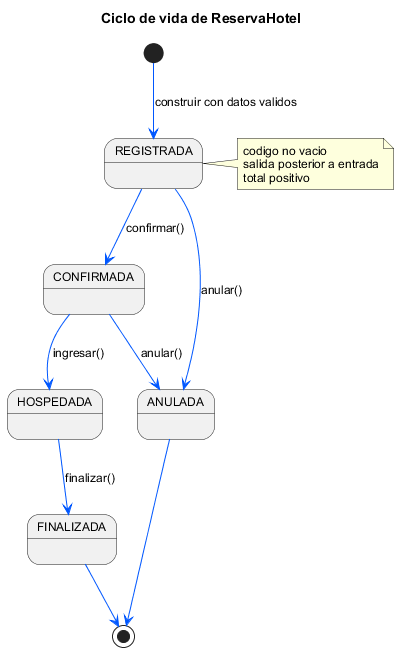

In [ ]:
import base64
from IPython.display import display, Image
display(Image(data=base64.b64decode('iVBORw0KGgoAAAANSUhEUgAAAZcAAAKUCAMAAAD/xIUMAAACB1BMVEUAAAAAV/8EWv8NDQ0LW/YMX/8NYP8REQ8UFBQXX+oUZP8aGhcaGhoYZ/8caf8iIh0iIiIgbP8ncf8rKyUrKyssdP8xMSozMzMwd/80ef88PDQ8PDw4fP9AQDdERDtERERDRktAgf9JST9PT0RNTU1KTVJIhv9Mif9RUUZSUk5TU1NVdrVUjv9aWk5eXlFfX19beK9clP9kZFdmZlhlZWVglv9kmf9paVtvb2Bra2tqfaJsnv9xcWJxcXF3gpdzgZtxiLV0o/9+fm19fXB+fn5/gG9/hI99hJF4g5h+mMp4pv9/q/+DhHKFhYWCho6HiHaDrf+HsP+Li3yLi4OIiIiLs/+QkX6Wl4ORkoiVlZWXmIWTuP+YmIWdnomdnZSZmZmfoIubvf+fwP+jpI6lppCkpKSnqJKjscunxf+ur5iur6Grq6utxvWoxv+ryP+0tZ2zs6q1tbW3uKCzzf+30P+6u6K5uqy6urK7u7u/wKa4zPS/1f/FxqzAwbHExMTHyK3D1//H2v/Jyq/Oz7PJycHMzMzP0LXP0LvL3f/Q0bXW17rQ0MrX19fQ3//X4fPX5f/Y2bzc3cDb29XZ2dnf4MLa4vLb5//f6v/l5sfm5ubi5/Ln6Mnm6vLj7f/r7M3s7dDr69zp6eTr6+vp7PHv9P/y89Pw8ODx8fHz9//3+Nf3+v/+/93///8sf0OkAAAAKnRFWHRjb3B5bGVmdABHZW5lcmF0ZWQgYnkgaHR0cHM6Ly9wbGFudHVtbC5jb212zsofAAABhmlUWHRwbGFudHVtbAABAAAAeJxtkkFv2zAMhe/6FQR2aQe0cIJtBXYo6qb1aqBLi2S9bNiBseSEqCwGFJ1g/fWTkrXzspwk4X0kHh91FRVF+86b+ExhjYIdLLB5Xgr3wU7Ys8B2ReoGelyh5S2FJbTo41CxrsXea8VBp9g5KIXQH9fn9OJgNB6IjccYS1WhRa+ubjjsmOIQuT6w964aVx+qi/8wFuvkD1IUHy+qaoCUIrz9V1yRdeC6tf6CznULJ9EoqXcwocZz8g4bspjPmYtONnjH6rz58f4nnJ1dwuz2Sz3/NitvSvgMyXxU6UnyDSwqR9igJ8vRDMBcN3mYVvXs61tdS9KhnJwecuX06X4PYej9jhiUZuLuYf54e7Nn0nbExWPUkT5/CzNQ1dPyvv6+Z1oKyfbLDhsImUuDm9dmr++QIgGh5UqB20EkJk1mackQOOXQEBuIOQ6ENUd1QmkPCC6ooEUDyoo+S6S0YeOChdzZXKVb/qtmdD4uxp/OR8XCKY5+A02Z5ll5DzjnAAA0DUlEQVR42u2dCVzUdf7/3yrDfSmgIB6I6IDK4UaUiq2YBlrYmjdZbLltqato7Pajf1u/frUVuy3lsbm2XpG3aa55ZJlgCR44hhyBJCKKqMiMcsg5oP/vNScz8P3OfL/fGWfer8eDme/3czPP+Vzv+Xw/n157AWWF6o0fAXJBIRfkgkIuyAWFXFDIBbmgkAtyQdkYl+Yy/LTZy0GkfGQb5QCj0lxhdp/dakfta5VyP41821ACqrCG/PXdZpMvffxXBnEr42zYq35lpNyR3G1pH/b6IkuXR0Z7l/wFIERqWgrc4kVGRvatftf8ci87aNv1ZT0sjQPlK/LKoEQn4lZR2C5VfZmVOe0BEcx1ZVkAfXGz0DFWQgFtm0AEvxhIx1P7F94EVQJd4xAiq8+8e2VStWvuPccIH02gXF+nMnBnktZOTbdQZXchd6yrdsK2xaWszj0OQLLOFeBTojXI/oxwm5hC16RVrQBD06n/exfRgviqLja9TdaQH0/fi4cNsrQgMp7a/50Ssl2ZbyQO89FS7rRr8DKiFYWVE9SBPvW92xlYzSStlZqqejOF2tIJny6t0UvYhtoxOfiTb67MCGC98zuf+568SX16q1qT10ZeXUNeK/Y6f/AlVS32+n7+gfJT0u0Z+J74mNyjdfwVTaN2/hNOGItDKC0tdWFntI/KNUeeuHdtSJVWIPn45BeYpLVSm01Iu1Av9YGVPjoJ21q/r62znWMi4AMf6jqnNTIR0hbkUY0TjJHC74i6dAaCLoJ/dTPBUTrgqkIGcaDj75OhyPkZ7hmLQ36y1zudl09QuzrCwcIRL0m1AxG1lUlaK7VI4q9Aq1BEJZmwSydh2+LiC9fJt339qA+4HYhWi8ZCXBP/r6RPp9rdkfzuQ34+MaAqJ7udhMxj54hao+OvTLvqPhzAaByADCLIwQlqV48F3169+kPk25pAzpqktVJ7mx7MaRdKL2Hb4iL1rsuOA8WezoFkM+0OdQAHL7wQRF3fIBqjTm+grmsBbhEXI2TTk6EwjOpzEredrAmhIar9s64SndNsMBqHkOT/pZTvmq9yhfY19bJtBVqBHDRJa6XGSLtQ+gnbVjv2Wvpn2a7FnZFU7zlhQ/nqAYeU/anrLVffjzoM0xj39X77iYtJe475t2d6b6SixpyGRDoRtT8xrJL9SHbsxuIQ8nlhw/6pPozrtJ1DF7hLXPQDqZJWp8ZIUyiXe7tC+ugmbFPzl+g03xJZ67g0+u5d35N7YTndYP99aEHm3dmzqOs33X/YM4/8TP/isCHT96904FnUeFbHf3JgeXp9YKfCaBxS8SGdH6tcZ025mv6Zw+v6geiktVNjpC5UHOxV6CcsinqJtk5J2eCjdaPU6ka1ulT1ZbPEYMOh8tf27iEO46rwlBgNZNDNVeNlpDC2wQVlnXZLFHJBLijkglxQyAWFXJALCrkgFxRyQS4o5IJCLsgFhVyQCwq5oHTlYJWlUhb8UtriMHBMtA9ysSJl720j3+pLv5qYJEEu1lJZ3r+hvj6Z95cg7F+sDgtAW3oZcrEKbbqhc9uxTolcrECVMj2Hpn3IxQrUlcJJ5GIFquji0laIXCzfjLV1dbuEXCyuKwbcriMXFHIxKEOGlwHIxeIKc0Au1shFEtjFySEWuVhek7u4jJAgF8trwlD96pKE/b41aImT7v28AORiFSOyv+iAeTbOLsfJfeZaXZG8467fVl37Lh1vn/MXa/y90jWl7EypHMAp+Df2WVnAWn/fl0qhOXm93f64D1Zsh3EFe8aC9jHkgkIuyAWFXJALCrmgkAtyQSEX5IJCLsgFhVxQyAW5oJALckEhFxRyQS4o5IJcUMgFuaCQCwq5IBcUckEuKOSCQi7IhXdpn5kLlatZxKjcZTCuwYB0gpoYyIWtlujcdbCIIT9nOK7BgB26MSwhB6v+/AsVET70a/Pt/vkeEQDN+TAByjplo26DfFSVFJqrpP2nQjNxF60bAVQxSOUC+ey5rHGglIwbzQSj0iJUNtiVTIf2J0QkyMTQCyiirPA5cUZfzYW0n1szBw1MLbi3tU/rmhN3vr0bVflm269bp50sbvVYc7p4YGY8FGTGF2Q8V0DckUfFa0WQFtAxyKRSKm5/7zx5+S35gRvRPxa3xtIB6LT6AGz/JRr2nX+U9r9RTCZIxYgHvYBYX+hvectqkJU3dqyGm8vS5DsluTuSywamQnbDrJ1pMuJea4dS4k4vQiLQMQjnbId02HeqIiYZcr8GIm42HYBOi6gOz/4N4MRKxp8SHQP0AyIXSkUBANHR6WEAAc7l7hJwaoKJ+xdKp1GfkK/Obj70nXaEQqBjEDo7EOCRU1JY3XDVi7qnA6jTCnIqdAKiBVP5q2J0CYhcKLnUASgrJOSOl0qGguv6svx/LYgnrtyIP+JTZ7bDdOsSwaldk04LGS53w4IgOVUfmACatCYfg6la/qoYXQPieIzU4+VK+Gb7b4uUIHNhdlnKzJDOH35LVUnuEj7GIkg1znGEczbIhsdLZdQgmQmgSWtaUdE0LX9VjK4Bsb6Qkk5Z7NX0gU/0Kz71rzPf/jl/SQFIhcB5C8n2R7rYKeaakQhazhETF7uBw9w305QRRD0InPd3OgCTFlkLhytdQeWviUG0iXoBxVOvvdZKZc5X6vZLqdWXKLvfJa5rBINRDQYzFKu79Ox4XinReoUu16wiGIxqMJiEY3o430f7GAq5oJALckEhF+SCQi4o5IJcUMgFuaCQC3JBIRcUckEuKOSCXFB2zaXKwBVysbxOnWYu8k8hFytSwif7qfcjH05GLlYkL5cdZI3J39LLD7lYk96AT05D/kfwJvb7VqUxvr3WwMfgMRa5WJdm9SGfpZuF42Qr0xQJgLLP08jF2vS0A/SKBeRibXqW+FuEXKxOzjEwytmOuYj/XFLzybtsgnmAD7uNDfpOZv8UxNth1vb5n/3Y0Sq4VJ53DA9kFTKE5SPz1UdhPNuHUkfNtzYu7UemO1oBl33u09h+u9nuZBAYqPxmwEN77rhj4oGn3C3dvygyx08W4NErySzHfQ9vBz/zh3YLc1F8NcdXmJRjRhx8eLv4xEP3LMvl0IuCPacY5lj28NaYZw3UGBG57HtKwMdHJx99iOcqBmqMeFwq3X2FTP7Zh7gl6/3s9/csNh47P011pcwgO+vHYiGdul3iCdUHbkLYM54Aa6aGNXxV6ThqhmTfJcozVRWW0Ca/GXRkSdBUT7WDalhmRoW5cmbBlW9STIppWrSunf9+vVGZaPWlWesh+IKoqKigzH1QMIq4iHKBgr9CfNzlt5QA+Qp4rzZ+wul0GBwVVewaFaUOS0xUZPuVZORRUSPOpco1DozCK00uW62M4G1aVCVf1V2vxohWX04+onXzJMFIcm4WMJOZ9TOJ7/3kFWfJWqGs/idAdIoyBmD3b2KJ/1sVFg6EXzueQIQgIs1I35imcaAVfCqIdWEKFJHEVPTnutEDiJscIGZ2vlPJi9iCSLUzNNb6FXgQ92qHi4Ee0Hg9DPLu9R/DJEJGU3mbpLqdzEX9/2ZYhMst/Z/qL7mprkobqSbuYxqSe8b0MM8tBsLmv371BxWG2PV6DsQne491WdKUQ7YujkmFgK3EFyLFxeuyF5Su3UpcfF27FRhnolibnfwvT0zWOHznuBgO1AxfOcC17DeL6URg7Va1t0larL7aaZn64qR98zZAjQ/xjX+R5LDhJrl7GNE9BJBfTsm7Wz8A6fPBXcLmOYeFbKtg3EM79Ry4KKdlNeRdru9YDTdSZhxzSIevzhCuR4mLA3vhGO1Mzbe2O+bsTNY4JH5IxF1B7h+Xs59JZLh2eD5lmf2UnoPy0yuJ4dnnLnQdJv4uwNWhkVQHnqYs+fGdvwfqh/0OMsDj0HLGKAZ6DlxEbh8XE5MeCjDQ6efzxM0jJJf8aKIt3QvnaeffEC5ujuDYpOUQ7FTg1CsUOlbXX/NiEsnTDs/rEM0iXMbGJIX9jegyXSSEILq1gmhb0kIor7w1IIlcPqhMP2xDydOjR0/MY/rZ8kA9By5yfQDQflFCTuY6XF06mM3lHG8DNBD1lXbWsvJoHCYdOzwZcv4pnft7VSIGwj/MXAi9AhtUl55TPi4lmvNKqn8JPJ1FXNcE6Yc9NjQhISGp77fUICjn0FwdB256pKIdvtk+sbidaApDJ11uhxOka3xRI9nGM86a0FoOCb8UJ8D54Qmh5xVMIgbCP8ztGPk1fC09jupfIDlhkfcnLeDyOHUXuHT7ZgnMC9YPe4L6sX9c1jQyku8LMaBy4N60j/ntEnL7uPN/9KlfCZGxS9yoT2FM/JI+Q4i2iXbWsr1pHDyGKT1g9ltp7aGtTCKXu4bnR6LtC7drVg/zAInBaw6i9n7tXjtVv7+0O2peGd2ojST68wx9Z+jqoLrVfzdPO5Osor7oVx8j1wLJUeuVUdunz7jvm93F2YCDo5F3m+hfrE7D/ldZkxpvLaVxQCBqMMOsyZRpJx96c2Vh9q5ddQYsjzvhymrmogfpnIRxZTXLnBUGcsT60lx1444SHoCbv8fISYZtlgto4yN50b2W7jLFYrl0l4Ec7ZbLzeqbTUDw6Bsw0rdLv9xYAKSJlLE/MjZLKpTKqbG67y9Uu0YbJakIFzvzYqBAQdw31oI8TGWxJG9itOOCKhBl9iRihVEhGG86I01YS3O5tEPoHMgdrhWN1bfI6gEDBkvdjQW88kFY8xfrgLE/AmOzvOwF7RqnDa6/2Rk/m7FZ0hGK4HjM201Dd86dWrq5j8PzKosleUNw0cQFVSDK7EnE6szs4xDFeFMZaYW1OJcRQi/Ob/ji/cswYKj0mR6HrSUBqZDVWEvbHykxxssKjVPdJx7PLJ3NGCXpCHP2vJlz5zNQpEwlLZp5aoslcUNE0MTVCpSzM5mIlUdcXaS96Yy08rH9dszTl5hXKmrlB5VEdXFzH+zvYSzkhIMvjEjw8aHtj5QY42WoxmmIB/jAFcYoSUcgwzW/TUx0FOBDkmA86RutuKpAtNmTFBGC8aYz0srHTvoXH2blZXNd9cUmsj3rGzDIQ78Cea+/mL/urtvG+UFy5kvLnF+Ro3GijrLyZIySdARibuMYvII0x1ymfjpiPBvo35E0cVWBNBm6qb3pjLTysbN+39V1IH3RVFVwl6pA/n6BKj6Z8tTQS7fqhifAamYQO+lf7Y4ngDRJqpxuVAfmePhM3NDumOccSkcgXMevAo+L6V/QkRjPPKbKqePqBFKJ8aYz0srHXsfJbqG0qbe5prq4CepeI6+fS0sBWNlA2x8pMcbL2Ronpw/dFakqoyQdAQbO/+jJZf63/sAkrWux1MSN1A5ENHXzkzTedEZa+RiTtdgteRAHu6UBs6W2BzGOXfcFc6kfVCeSsRtDlkzjEZmyJaF9zNGYvdGxy6V+UEcjwQ3FBTZh7dsOw1Ej/4D2MWuUdyxyQSEXWoquV8aNvFdWk6FYm4+Ri+la2vWqVmY0tJIKpUQuQutiJzkX/DmrhrnKyypmfBov1mRdAcaTuM3JIa3NZCjitZFwKFV5CS17/L2SNAzTluI24oo27tKrpw2ZkUvXziBCla6NplbBhpm37NUeuTixDThnz5uMMfgr4oo27jKr2g2YkenwqlWwAi17xfrCSGUM1jYEg0Ezssr+SK+C/a8wy14tx2VAdaCwGcjduITWLF/VMe4aMCP3VUWZdKzXZKGWvVqu3489L3AGhdFcQmuWrzLrWmndqAbSjEx7ZmaELgjWnItMrYIVaNmr5eqLxFHgw2yvsF/7NXD+R4wxmLjSMe4aMCOXUuGBWQUr0LLXLhLvfGTFMUEtynntLPa82Km9D4napqsx7ho3IxuKx68sZU/2GZAnYOoNMs5bkTh2udC6MWpxFmbZqyXnlXG3CgRLW/nVEj6SsbgZ2SLz/VmKLKFqy5dzeOm8vGPtkQvEB22qEKRv2bbIB2xL4s4rpdKD2cOk/E5k5IUXI1IAkItZSoSbsh+Njw4f9Dh+7BKiX3Q8AHIxWwGJRr1u//mLHtrVjmXvmbM1fP0u6yVRb2Eu3eiL0T11dw6zPvinGUV+7aGpL9b0+0t9/ks9hpky9EuwB1kTl21j+vccKOVcPnIRt7rkzGNT4D/9pwO5iKmvg0PYBBs95hPkIqJas5PYBVx8KR+5iKe9g0azLPKKtR3IRSzdz1rMNujoR9YiF7H0bcBg1mEXFeYjF3HU8d8k9oGd/7gJuYij3d6jOYQe53IYuYiiE8mcgr+6ux65iKAjPWwzoK+QxzYjFxF0cDbHCIsK65GL4PrJnetJlc5T1iMXwbXz95yjLCi/jVwE1mn30dwLPn0dchFYX5uy4m9mdTlyEVT59x43JdqULchFUGW+aFK0Z6vKkYuAKm4bZ1I857iDyEVA7U00MeJz+fXIRTBVVU83MabX6EPIRTCtn2dy1FnHkYtg1eX2FJPjhrieQS5C9S6TzIg88ThyEUb1ReY8RZZQ1opcBNHn8c5mxPYK/ha5CFJdLj5rVvyYc8hFCG2e7GxW/KeutCIXAapL/mzzEnAYloNcBOhdHnM2M4VI5CJAdSldZG4SCWW2ycWizyVtjjZYXXK/84FunpjM9QjTbMnr5Z0/FusLz9Xl9FyD7hsiI7pZgNy8J0JSp9ldL+YCtmM8a98oP4DCbHLPHOq1ubI5t5C4vucfOpW4qZQRDtmVUJnbTISQZZdRbvDlEwALNT+JRZVgO8ZzdTnxAXWEdOafolNhYOasxJKNTgHlE5Oz4eSd3dtKNvZxeGGjm9+mMc2w4QvlCn/X7dHRhFv0mQwAn87KIFXH/48OB+TCa3UJHgy5LatBVt7YsRpuLksE+U5J7o7klJNpZDNF3MjkayXpdenwh0KnmGTI/TqacFO0kFsoBJapuPQOPjcOufCo+yffoo+Qjo5ODwMIcC4Edwk4Nan8yUPGCQcJ0dZ5tUfA6oarXqTbRX/S07VY/dB+xM+2yMVy/UtmSAgAeZ64skxCHhyt1NufUmf7vdyPQue+RLk5tel9n8Zfwn6fR3Vk/454fbxcCd9s/22REmQu0m5Cy4bHS2XUpnqRcmpQFqH2GtxwH9sx/nQwmFzLJ52ymDxCOvoVn/rXuws99800ZUQLeSUZQHb5l7W2tQoosMEZjHj79elVl5f/h1ljSW+v2OMmi+oAB6tfg7Lt72l89te9ZHtcLNWO7RugWvoq0XrtRuoAiaVK2P6ylk9QASAXvvTDqyZHXVLaPCFI6z78DvYvfGm/d4jJcYnxgc7OVg79ykOwvvCjI8/xmNjQ84Bc+GnF3PicCwaVIxd+dGA+n6mNuIVc+KkuHY/zmVxoPXLhZ5CcyGtyDv2qkAsPyofp/CY49Apy4UE7EnlOMOgacjFfxXU8VxcYUY5czFfmPL5TDKlBLmarvG4K30k6KzqQi7na/Tv+0/SpRC7mVpdKAbZtH4RczNXmeQKYSgdWIRczq8vdKQKk6l2HXMyc6j8lRKpBFcjFLN0uSxQi2UFNyMVUUVu4fjFRkB/i+rbcRy4m6giQj+0tECRtB/dq5GKiLtQCbHvEWZjEveXIxVT9B2plCwVK27sSuZiqYtgc4QVw/6daASYwtjZQFnE9TMfhC+tbc/7zIMkP64s1cYHdA/5R0QGvCjGx9KhHLiar5U6NxPktQdZ6+WM7Zg4YF7f3/ARJ2asJuZgulwHvCzRO9utELqaql7P0TaGGf84tyMXkzy5OwOchXGzs6VdT/huF7K4pWQ1zMXoKblu/8CDz/g/XO/3tnEtu+RCTTgQfGd6Np7ziqN8ss+rLbfvmotwUnWRaTt1hAV/fmOr1cVLT/w9fpW31Lxw7YsWmOZEClSRwUaUZ+1T3UtgzF+VXczyFK8vkoftMHyg32jOXTUJiAQgbmm1y3Do75pIb7SlsaSLvmNocSR7YMZeiSKGLM+OUiRH71doWFy7jMcUwzXXFoVq3aSSmiv11jhMmgzJjbjBAwdUZkE56j5i1ZmqYMoP8Ij8Wq8wYQY6Bs/JSJURT6DeD6KcIH0nQVKr2UQ5aXZgEUNzqi0wzjs15PzB+1Kqj5IV3/KP7CRYFawjnmwXExaioqKjBkE+0SAXEVVDmvpaC/eQo9hvyOftqGXVNBBpxLlWucVApOguZcK0vdwM1s5jFMUTbsTtBuWlRLMD41JzHoHMHM7GZpOmEniS+/JJzU2HQ2ViooLI6EH7teALxPk0CM9I3pmkcVPOQu6b9H+4t9ltfNDrrQGCB2LXEBYEFPMcS46iVRwwvrrvkRoDLAch+grzLj5v0g8ontljPwQx5NNlvfWlTX93z0b0Ivkb8xa1ZRd2QW+qs8qUu3wao8SEqxaQ9SsmFD3YC5DmHhWyrCKYjh3bqOaBMtsPQclR/O+kHT9rJznrRih39yJtVXurdXJ6D8tMrfRvAc9BZH2+yefsOMsDj0HLat1rfAWVmOxYhJ7ts+SvK8Gpq4dapIPJ1Od2SOUokqjHV2JiksL+R3fqknOwJxFtDydOjR0/MYzr68kA9B5SZXHwjVzeAcvUQSeC4dALMJsUcqjWbfrJr0FdgAzkAKCt6kng7NjQhISGpL3UIhTLn0FwdB5TZ7Rikrlni0iJNIerIuhUuLYPe9aS+8Ul5Bibir6UTNUUyyJGsQyeeJp3GZU2DFwm4L8SoHWYgCV1x2RcuU9vCr2xxYVorJfA5Fdxn2hYl+Ts+xvpC1QM1DJygW03/gkIuyMX2VKm70iO3UJmJXKxAcp3jx/ROwkAuIok88oI5FKOZvCrTOBs6CcNmxmPXdohQoJumRqSPvHiNPhRj9M4MKNmZoXY2dBKGzXAZkiRCgUxcetHoVkEdeQH0oRij1R4VRk/CsM35i5XpnouUPvJC91AMcldfoydhIBcxlLthQZD8a9Vdk+pnCcbZ0EkYyEWUXn94PBxVLafxvauUyPScmZMwYpGLiLrTP0F95AWhIOlipxhqd8XuTsKwYplstxSs3zfNbrkFXjK2lMb4SRg4fxFeEqMGVOMnYSAXwVXbl0Ug/ZMwsH8RXA+cWATSPwkD64vgkvuATQnt/MhFSNUFIhfrHPAjF2vUPexfrFGtkt72y6WfCJsVyk1bXdPoBPbLJVqEY1YKp5lWXxzsmEtAmQj9hKtp1czdnsfJgYJvH501xrR4Cm975pKYLXBp5HelyMWE8VicwE8/fm/q+YlN9s1FCoKeEb3pGZMrWl+75gLx5XnCNWI75pg8OawLsG8uML99n0APd2X9mGz6nL3Bw8a4cB73xymOtz+ibyRsZPmxNLkZqyuy9jHm/DTS7GfvXMAnUZl1RtfpRt6TrMC0H3vU8O5tbe6TzLNv3fOyey4AEr1vdv2f/8Byr+qB2cI8eVzvZmNY+LBb3v97FNstxKfAbkH+iwZn5NJF/25ezDrsisOC7HtUNgi56Oun8//HPhG/eZ8K8V80uiIXPVVteZ1Ln/u0cpsA/8XD8eyEqFzWJHAzNb5xXICjJ+p9kIuutkg4nkLtN+Vv/P8XNcOQi46KT/4P1yjPt/I/JmvyQy7a6vjsj9wndG8f5rslqwccJ+to7cjHuUfqP/MfPP8TVf0AuWjp9K+LTYk2s2k/v//ELT/koqXWzX80rf1I/Ybf878fjkdZRePy75CxpkUcPCWD13+ibgBy0RqLFaWYGvX5zh/4/CduYX3R0ue/N30U9PbuVj6nL8HIRa39Hk+Ynm3/6en8/Q+tzr2Ri3rOsN+sJxVnNv3E2/9Qanvdi+lctsWZd0DoG1t5a8l+DUIuKtWeX2Bexn7TeRuTyb2Ri0r/mGiu6WNmHV8tWWUwcmGUX7PA7Kzf2MqTnaxmFHJhtCPOfEuh36R/8TQe80IutMrlL/CQ9/O3eGnJqnwAudDal8DLc0BvbLnNQyqFg5ALMxi78CwvmQ9O4GOT8F9DkAut72N4+h1qXuth8xOpx3aM0YlEvrJP2W3+mKxailwonXbjreUIiTP7t8vWtsHIhdJ3v+Uv/+Q7R8xM4YINWsdM4tJaNo3H/JfuMtNOVh6EXCh9K+Vz9cmYsWbaycqlyIVSAb+n8S4rP21W/Dp/5MJ7M0bI4Y//6TAnfk0IcqH7WWeoXM0hQk+ne4yLXtuddw9nhVR5OyMXUucfBdWxlazU8+keSy/nd+Pbw1khNmmFMYXLpVEA/afSx3mQ399cKKSP8YDCbAXxwREOoD7zg93pHos1LRl9KAiVttZZId2k9otNNmPcn6+svzMWoGTVCuo4j2RIcfH+umZbCXmMxztNQ7Y/P+xvYc1b/g2qMz/Yne4xesyX9GIB1aEgVNolqrNClN2lVvU0ciGlWuRAHeeR/J1DOhzcTd8pPgNFyryBqZDdINec+cHqdI9XFz9Bfe01h4IQaat9K7pJrUMehlyo6UI0/U4f55FPdDZPElx8JSBreocYrI08vFA6zceHOfOD7ekeDks+XEd238yhIIaPCjGY2kXf3siF4jJb+05SQz7lANQxHsNTyY9sfVn+vxa4M2d+sD7dY6z03yvB2Fkhud2k9ouNHkXO+dt2LVT77pmiZmBOtxp/GVyrlmRmSOcPvyUbHi+V0Wd+MKd7RPSQbEo+OSbTikedFQLUyKu71MrDAesLOat00okhnfZHhyH0ZUTCEv9br4z9SwpAar3mzA+Wp3s4v7ju3w5ah4KA1lkhc7tJrfIV2+TC5ZwRUmf26fzEeLM2guiSVRYu6kQP+lgPzZkfbE/3eNdvqU48bRlNrX7Zl9iOkbo8UOe27ZN93215St3bqF+0zvxge7pH2tlyMHZWiNHUCmxzVgnQZy638Cd9dHoK76hr9fMe6z5K8C2PB9EsWlT/9Wy2hdNN7ZD/WNvkwrV/qXxO9z4oqMcobE/3GHdmy0vAMbXipTZaX7i2Y/cEfJRx2clyjjFqm8YgF3pOISAXh1e4LsAsGAzIhVKLkGtOx/lx3HKhbBRyocelwu4jmfodtwWYF5ELrfY+gpbG+ZUPOU1y5ZHIRRSNC+DSkl0Y0Bu5UKoReiPJlB84tGSlIwC5UFJKBC6P88scWrKScORihS3Z/esxyIWWR4vgJUo5zHZ2WWCbS2FM4eLVJniJnGeuYtuMjQTkIp5mumxhyeUR5KJqx9pEKNNfs9m1ZDdjkIuqkWkRoUxeL7JaSv5LgDNyUUmUY1WnuLMZk30fAchFJfdaMUr1xuHuN/SrtfXuhQuX++RLnwfka7nApfKb93fq3djz/a1nCDZtIciFVDu5ksibPPM1v1LoYj3tQG1NetKIt+dxgHODAblQfX4+8S31VgBUfRgreLlS99wmaugFI88NeF2oh/xo5EIrKeMwBNyCjtdF2EZ68O8+BKiGc8b8N8Nlgkv9YeRCVJjAL077X4U34VmBC0U+CTvPdT9cgZ+NDQtPXe0zGLb8IQK5EPoEPrlTu+W6y+NCl2r/7npYvKf8cq9LxqY4sHvEL386Mslm+xhO68d6PSj5tfkyOL0kcKEcwm79795HAv/bXKucaTjEybraPsfvjn4D+xdK89wfdHS4i/Crx5RlDz7cryh70Gqk4/cDZU2j+zvY7zNaTsz3O8eJUK4ndge1NBJQLhr2HgrQIvm/3siF0diBRK8sirmw98evOgA8uGDYd2QvkLxqyxMYrl+5txxchon0NZ2y3tvB2DnZvuAS9VtALpqGfWzLBLHK5rUhptdVI8V44PlnW8bSZd24Qna3+wjeUL2LZdpt/cKDuJdIuwQBEQVfOhoOJt3DU34PA5fc8iHSwB5ijGRfX+QVR/1mcSuPfgluOhk+C8l/Aj/5Wau0nxdTbgrnvUuvPpDAYb8j5aZoM1dQVh+Nk9oYF8W2hZ4C5JDVznrXRcVXczzFzO+h6PeVwmCByUP3sa0tfGDhkN/DwWWdMFgAwvyz2QXcNIeXEoQNzbYhLrnRnkLlEVOjYNXl81WCyDsK2+FSJOAsfsYpNqGKIsXN76EYJys0Jwynp0oACsqJAWfF/jrHCZMBGr6qdBw1Q6Iklw/5xQUDfQbVEhfiXhI0lfqWb/KbQXQQGgfqXiUJm/XmCu0zjpnk5gYTJbk6Q5nBFEmZkabjr5e/VlclsZH6ItOMLinTx80LADnve8c/up+A8F5t/ITTxHvBqKiouneqqfeoKBfyfcS5VHJrkGrZfiWAxoG5Vyk8q+eSaJVAndwasiQFmiK1FOj66+evUnSWrbRjtwINTCYWLYpN+OByjrI6LXbyOxXEPz4tISHV/zz1npAgId9npA/fSIQ9ED7gOBlH5aC6ZxR4t+eS3NUqgSp65w7DYfWz08/P966tcNFWi1KpbAc460Aur/Acmw3uGaXguYVpGjr0DCOxxcRLftykH7QdtO9NkCr6yiMV3fobzN8G7TC0XiVfQuAefR5B8DXJu1s/AOnzRFu/hnxkfjzAi4S7+wY6dGgnQJ5zWMi2imC1g849S2mtfFZHD45bY2hxv352JuX38HH5kqgZR3NVm4u2SyAwTVny4zt/7w9BAKPHE/3s5y5afQHx9x1kgMeh5WoHnXvu0kRftGKH2j7W7tjV31D+NstF1Vlnyn2Jt1Mj8s4sl0RGppX1hxlMW+aiNdwpD4SGkmSAgCNKlYPq3sRBkXZyy98ZT47nqoi6cF1iwF8nf4ldcAkcl57mC5sU/6/x9JjJUFoTZNB2cvbQYjg2NIG4PP3tNMZBdT/DtDJpJxc8/eAogKF7UiXVRXMM+OvkP8MuuMDydStcWga96+m5dPtmCcwL1oxEyf4Fkp8k331fiIET1J6s47KmMQ5bmXsTPydNcoSS8oiXP6e/6Nw6hZhJAXkMoPezutmpI9gQF5U9OTPJoLeS2fpLCea1Efvm9xjESAlUBWlxkfCb38NbX0CzIZvFW26JDfUdps5fUMgFhVyQCwq52KZU47FrOwTN5hqLIHyW4KatcBmSJGg2LJZC8FqCh37pBbZjyAWFXJALCrkgFxRyQSEX5IJCLsgFhVyQC8pauQi8z2sbftKmcQmsFjIXuXvPYfrxWAK5xFa4hF8RMhfZtJ7DRPNYgsJptsIlqEzIXNpdew4TwGMJ7rnaChfwqxAukyxWpxkGVoib38PBZdZR4XqXu6y2oEjMFje/h2ScnCDYM4nfs9yzJY6nEnw/H2yIi7S9QJgsNj3DcnQkhQJ+8rOteWVieZ4QjdimOT5sw8bzUAL5Dvb5WbG094Mdc/ncCL7Pp8y6+Lw7+9DmlyDr4kJXG8Cis88VgOJU+yOBbKM29XhmolzWPoZjF2y8BB09H31uQn4PBxcAZRbbR9/bj0x37D5Em/skE5oUIyVoP/RMD9mZmJ91Sv9LKIlnHfV0nCAbshopQfHpF8GOZIY9uW+1mAX9ZSQgF1byFnVxdjlyYamhlWIW9HIEcmGngFoxq4vTYOTCTgPF3LSoaBAgF3YaVCdiOX8NQS4s5SxpFXE4Nh65sFW/UtGKWeUwGLmwld8N0YpZFgDIhfWA7LZoxbwWglzYT/jFqy/nopALa40QbQLTWjcWubDW4HqxSpk/AJALa3ndE6uUP0ciFw5yF6vjvxiGXLhUmApxCtkqj0EuHDRQJEt/uW9v5MKFi0gWsnOhgFw4yF+kCUzJb5ALJy63RCnj/ZoQ5MJpAiPOQLnCzQ+5cBqPNd0Xo4znBwFy4QZGLkYZCx9DLtzkJspSpdtS5MJNAZUiFLG+LRC5cFOgGEsvCgb3Ri4cB8piTPiLhgNy4chFjF9gLo5FLlwnMHdEmFXKw5AL13GyUvgJTN4AZ+TCVe7CD5SvDgXkwlXewk8sC8KRC3cuNwBy39lVuVrXubKLC63cQmUm1yyuRyIXzhpYA7Ah8nHmqEu15Of0XSg174mQ1Mm45VBuh0ZL6PF8sR4HZGeh8J5/f5jafLt/vgf5iIqscSBpNuk/FW6SfY9vEO3SfBvk0V8+AbDwnWhOOZwdCcjFlAlMNpz0bVy1YqNTQPnEZOUKf9ft0a8BlKzaVphHdA6zA2mXko19HKLPZAD4dFYGccmhMgq5cFf/Bkg5mQZE2yTfKcndkVwRkwy5X9N+8fGQETm/jHEh/BUt5OPCgWXcuLyIXLjLt0X1WL27BJyaQAqrG656qXx3Xfun2sVXAhf9SUfX4ngOGdS3DbZLLmb2+73ddS1kuR+Fzn1JffPDRxK1ixuAUxv3r0JuMCAX8ycwsuHxUpmCvi7c8FdXHZdIKmwzpwdYi8Psk4uDuVxu6FgV576Zpoxg9jDdce+vSpAu1rhIBpBd/uUlXNK/8px9ctHfh4SrNvd6Sdeh62HrGpeD1a9B2fb3uHQvy77EdswUdXkGputeYxqXxFIlbH+ZS/Kl/QC5mCJuz8AsKW2ewGmUXDLCTrmY278MbuASWkrMajglX5qI9cUkeTUKWbr712OQi4kDsioBS1fi7YxcTOQi5C9jv4wE5GKa/IRcElMZjlxM5SLkMzBlkcjF5Am/cIWr7eOHXExUkIBLyEqDALmYqGABH+I/Pwq5mDyBEfAZmMvRyMV0MIItVWptGIxcTB+QXRSqbBcGAXIxnYtCsG5/NHIxXf0FGyiXjEIupmuAYBPLmkjkYroEewam3Ks3cjFdITVCzV5CAbmYJnLq4gzUdr3lvBetUopcTFR7PvHifZ14ya/kvWhlkcjFRDnnn6GXXlR9GMt3yezYaGl+/5KUcRhCLkPH68D7D4t2bLQEs9ddOAd+0a/vr/AmPMt7yc6MAqwvJusT+KRJvuW6y+O8l+xSOHIxI/5s+Kb6e3DgfYew+rYQ5GKG5rk/UHa48//dLhgAyMUcLe8F0DmO94IVjUIuZmnsQIBW/pffVYYiF/P0loPLMN4tWfevP4pczJPf2JYJvJerxNvBrrmw+e8Vsu63GfOG6l09p9LWL5zDTNF+V1qy5ZJbPkTaw4Z5I1nVF3nFUb9ZrGf7scilOyk3hSf1mAi7ZszXN6Z6dQJLI/HVRfbNpYf+RbFuDp9DrcAllQdZBbwNg5FLN7Vl20JPfvObPHQfm2CFAwG5GNc6vrEAhPln46zSTC650Z785xhTw2Jh0+VI5NLNt1aQp+hmnOoxSIci1M65dDceUwxTX6aTLyNmrZkapsyYGwxQcHUGwCY/4kWZkUaFWDMVDpDvrstB7QMgCZrqqbpXSWLgGX/9L8QAB6wvRiXTjGkLRkVFRQ2GfKIJKlhD3N8sAKiW7VcCtBTQIfIVnkSQqFvXQOVDRhpxLlWuvlcpPKvHWaW9N2PdcrmlNZ2clJCQwLRqnTvo9wPhA47rDIKJIO1NaVo+0xJmpA/f2CVkz7uUl4YhF85aeYQ+7i0/btIPel4Fe/7kq+cTW2wwZPeqiEYu7LRk4cKFzAMVwXFkSwZ5zmFP3tI9kE++amGkvk9op6GQ3avKx967F9brLlZ5aTZ6WbRiRz+A7yADPA4t156F/m1MAvmu41NtKGQPkg0H5MJOjtpDqOXvjIeGkmSAgCPa/fkah1TyTdenPFB1L2FdqJLHkIspkYKnHxx1bChZN05/O0nt+s3Fj6h3lc80sgqdPbRYdT+DdfrXX0EuJsVKyoMTT5MX47ImwQLifWkswKl7y0innSqfafAigO8LMVuZe9Zc6qG/3XPpbl+4zCSBMt03v1vvM8ffsnsu1viISUkUIBcrLFOhFLlYI5eGEORihVyK/RGLNXI5NwKxWCOXS9jtdz9/ubZDoEyvdT+rDEMs3XIZItj8pTvPck9nxGKF7VgRGi2tkosMZy9WyaVqAlKxQi5VTl5IxQq5FAUiFGvkkh+JUKyRS2U4QrFCLq330GhpjVxyhiETa+RShkZLq+RyEY2W1silQ45GS2vkUuSLRsseubQIlWmbUZ8LoYikRy6BAh2FJHc36lWCs5eeuYRfESZP2TSjXtdxtt8zl6AyYfJsdzXmUytBoyWLft+vQogss8YY9crD317YcJl1VIje5a7xD/8XNMKwGicnZPGf4/fd7BFz5REkwoaLtL2A7ww3PWP8OZj6Jqwv7OaVieV5/DZim+b4GPe129PDuc/357fvU/LY5f+4qBss9nt6eFf1+FxSnOJ4+yNcf9vtMJSsXNY+pvvTxO329HATuIBPojLrDMcJypEJXffWb3Of5NN9NPs9PdwULgCSeK6p3lIsM6Es9nt6OPf+xTS9WmbKcTD2vqel8Fy8nvrchFj2fYKFGFzgpbp87pEqYpGHwFxgZibnKFVOfshDaC7TO3dzjSLDZkx4LpB0tINjjIKxiEN4LuPYbfyq3b1EIw7hucCSo62cwt/G3UdE4dI/dCen8IWDkYYYXOC17NtcghdFIA1RuHg9tYVT9zIUaYjCBZLKOVhjWuVotBSJS+95HCpMuXdvpCEOF5jSwP4Hgl9wVikaF0jaxn44hksuxOMyrtdPbIPewKVj4nGBl7eyDFjlgNMXEbmM9TvCcvaCj4eLyQVW7GVnjcHHw8Xl0j+c3WZZ1/EBC1G5wMsn6tl0L6240lJcLl6PbWYR6koAohCXCyzMZ1FhirC6iM3FK+7TngMV40kJYnOBBRU9ro25r8BZpehcnHteG1OBB/GIzwVmdvZkjSkagyTE5wJJPf2iXIDNmCW4jHPqwRpzFWf7luACyfu7XUxW74wrLS3CZWxgt4vJcnHTMctwgYXdLibLx+f3LMQlpNvFZNdxpaWFuMDLPxm3xtR34G9iluLiF23cfJmLC2AtxgUWFVUZ8yobhRwsxsU5cb3R2QtysRwXmHnHiPnyfg3uaWlBLvCikV+U8fFwy3IZJzFsvsTHwy3LBeZsvW/IuRSNlpblMrb/Vwa7fVwKY1kukPKDAfPlbcBZpYW59A/6squjbCBSsDAX+JOBxWT4/J7luXjF/auLWzk+YGFxLpBcpv8sbG0bLh2zPJfeT60j3+jW7Aw5CjiHvb4VcIGk6mLild7+N5DcQuYK/vZiDVx6z9xIjsFoLv8lGrVLQQjBCrjA9M6f4P6v9+m806C1JpJo1g4jCEtzgaSd9ytATl0GNeaXDuoNn/0Bh8r66jNX7BwH/1h7tyiKeq7i9q+lvd1d036dPR5BWLK+dFSRI7DkwwWgoO4fh7ac4vdg/DzkoC9R12s7XHkdAiOGDCoD+jflYGiExsDOFMRgWS7wRGhKzTGXjg64QVdW5xaQNPwfbkBi8X6//85Yj44WgDr6th+A++9xYmkN47GlLzl4qCb8MAICw55ACFYxTh73qVtfYFbFTgLsXKyhf6HktfYz2b3C/NK6DvCGGdi5WMn8hVCMovxGUPzvZ8wY2V56yH0IUuiqXnstkOnqawkTVWuTCnf4pSIGK+hfANIb3p+qXjIW8b7yfcRgDVxWK9O0DxaVpEkykIPl+/3ca++TJ/IVHqjucOg/m7RYpr6dOwFJWLq+fJ1M1pb166o7oOPGugwlUWOSvkYQluZSKCGryPoLHdRSso7SNWQf41aIJCzMJf9REs4F9QK/S+Rvl4+eQhIW5lJKbm2h9Th/BzlQD7+EJCzMRU6uEq/UWg9LmjCD6pGE5ecvRCUxco2yLBcHi47UkYsB+ZaR7ZYWDG+yXfNCEhbmEkau65uuVV1mEy9FuOGFpbmMPUdOWKKcVPcjyPWW53BBjKW5RCjJOeRr4XRL5hC2nJzONOECMj2J//uL+66JEoDoIbea7jv4J8/sA6Bc8zv8DaabkZE4miDLSCPARGiqSIYfmi2tYJycIklXat0q05X4w5gVtGMAsRf2BQxQ3RSu8UhDDFbQjpE1JjdT8ugYKTFvKTrX9Bw2YgZkkd/3yWqSXyoH8BoxHkdi1lNfQKfbR1lHv49CLsgFhVyQCwq5oJALckEhF+SCQi52qf8PCcZmub6fFEcAAAAASUVORK5CYII=')))


## resumen informe

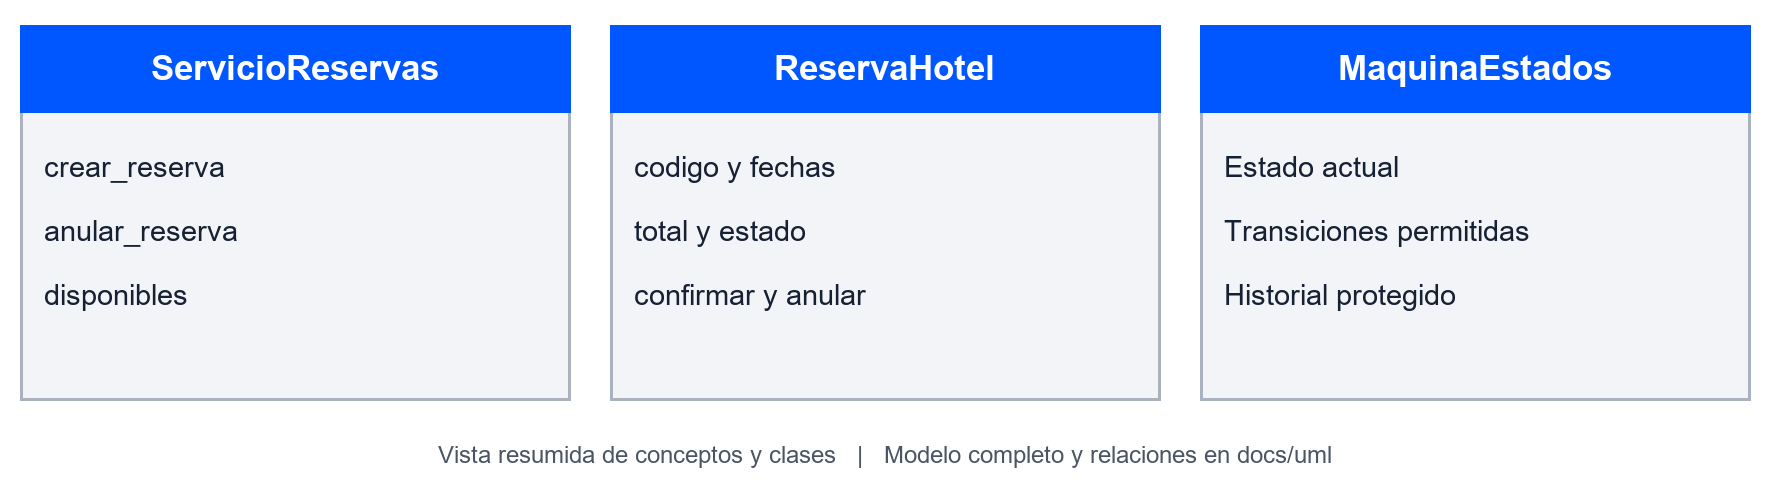

In [ ]:
import base64
from IPython.display import display, Image
display(Image(data=base64.b64decode('...')))


## secuencia CU01

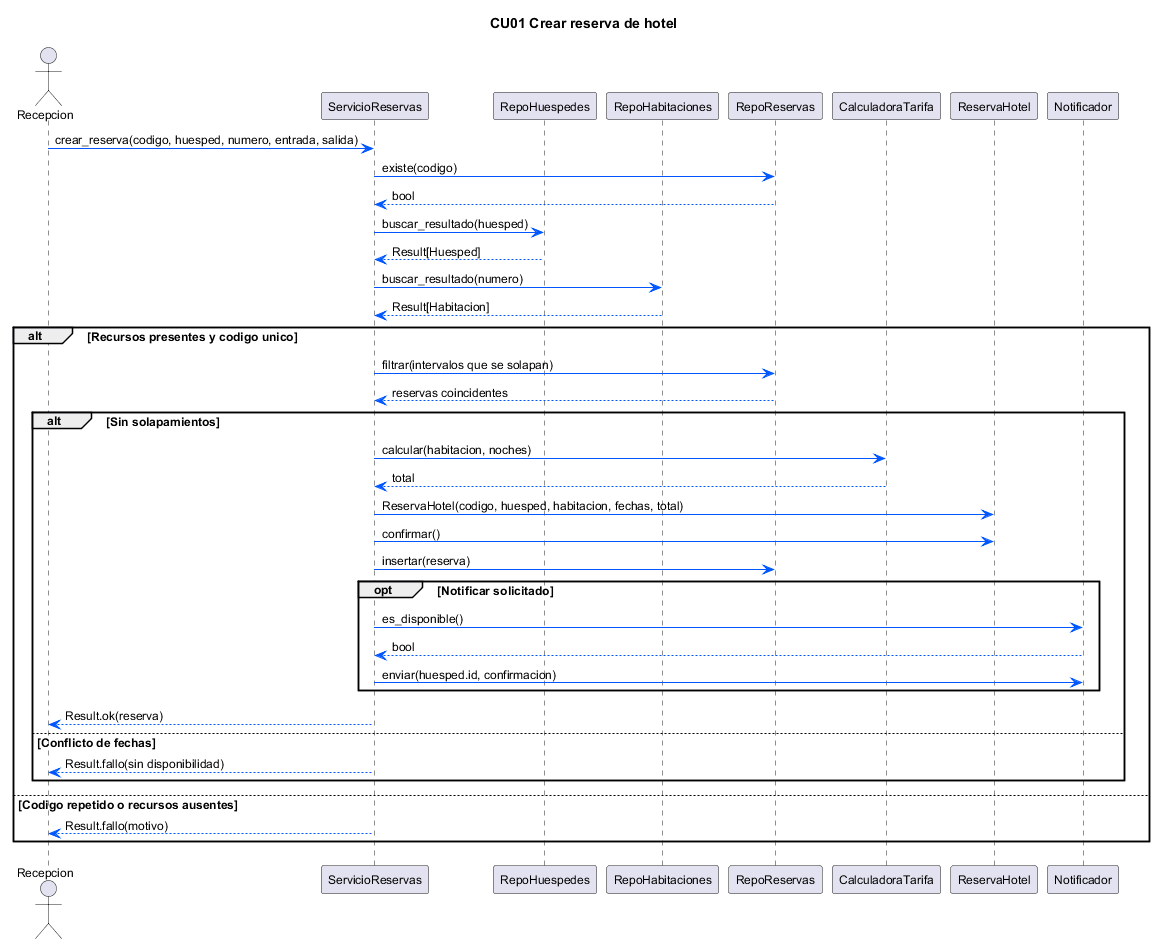

In [ ]:
import base64
from IPython.display import display, Image
display(Image(data=base64.b64decode('...')))


## secuencia CU02

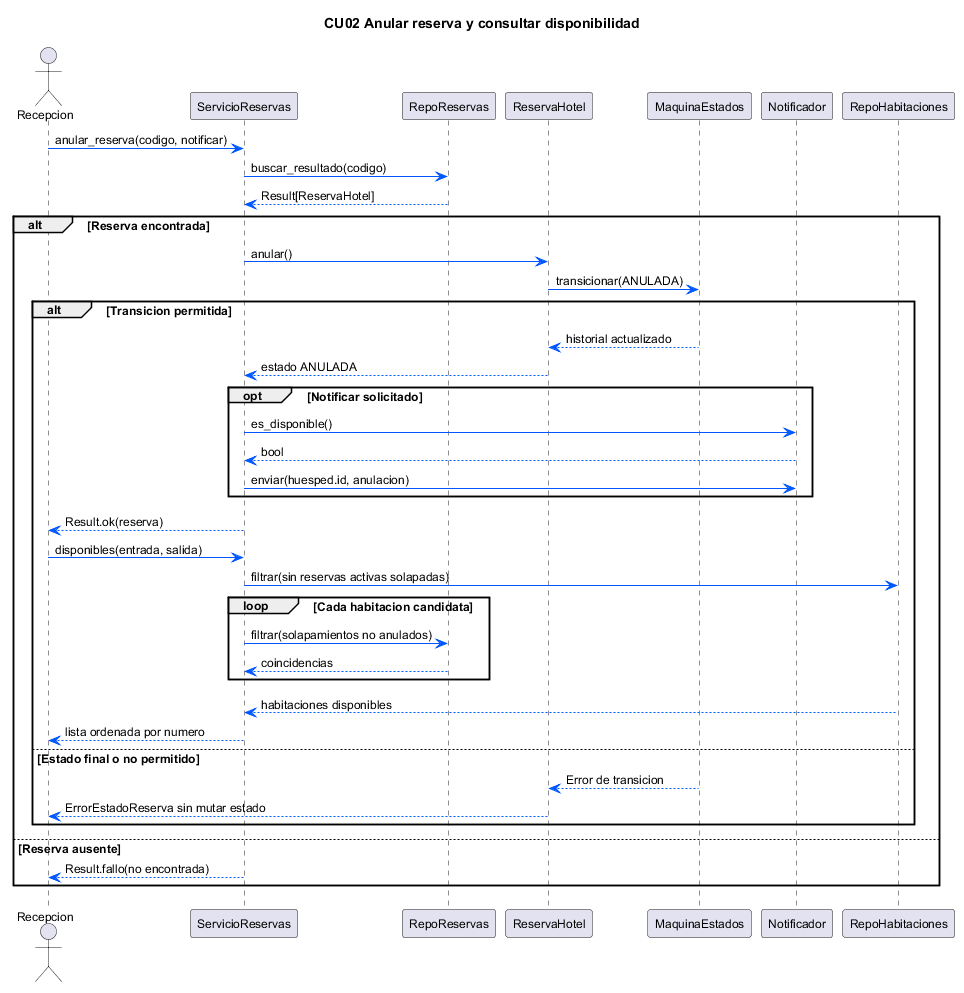

In [ ]:
import base64
from IPython.display import display, Image
display(Image(data=base64.b64decode('...')))


## vista resumida

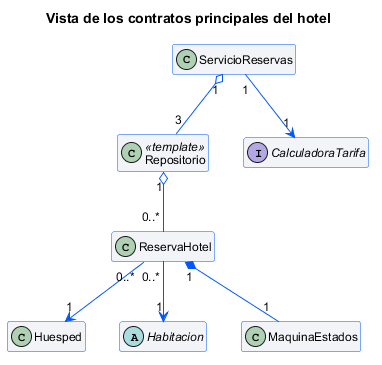

In [ ]:
import base64
from IPython.display import display, Image
display(Image(data=base64.b64decode('iVBORw0KGgoAAAANSUhEUgAAAX4AAAFtCAMAAAA3RvH7AAAC0FBMVEUAAAAFBgkHCQgAV/8FWv8NDQ0LH0cMX/8NYP8QDhQXFxcUGRUTGBgUGykWL14UZP8ZGRkaIiIYZ/8caf8gISEnJyglLCYnKiglMDEhOGQgbP8lcP8oJiwvLy8sKzIuMS8uMjIqTI0ocf8wLzYwMTE3Nzg2OjcyOjswP0Awd/80ef87Ozw/P0A4RDo/QkA8f/8+gP9BQUJCQUpATUJHSElCUERBVVZEWFlAgf9NTk5PT1BNUU5JUFFKWUxIhv9Mif9VVldWVlhXWFlTWWRVbnBWcHJQjP9ZWltfYGFYa1tYkf9gWXpkZGRmZmhnaGpld2dmfGljfX9mfoBng4Vglv9kmf9oYoJtZohpamxvbXpuaIhvcHFpfWxufHBsgG9ugnFrgIFqhohriYtsnv9xbIRyao50dXZ2d3h2c4V1fHdxeXpwgHN1hnh1jnlxiYtxk5V3mp10o/94doJ5dIt5c5B4eXp9foB8eI94hXt/gIJ4iHp5k318loB6p/x+qv6BeKSEeqiBgoSGh4mAh5WCjYWBnIWFoYmFq62Drf+HsP+Ng7KLi4uNj5CPkJKIo4uOppGMqJCJsbOLs/+NuLqQhreRh7iVjbSVjLiVlZWWl5mXmJqWnKaRp5SQqpSUq5iTsZeUspiSt/+Qur2TuP+UwcSZjsGcnJyen6GfoaObtKCbvf+YxsmfwP+kpKSmp6qlr6mmsKqhw6akxqikwPWjwv+h0tWl1tmm2dysn9qoprKvo9+sra+ur7GtsLGpx/6py62sz7GryP+t0bKp3N+wpN+0p+Wxs7W0tri2uLqzzf+w0ra30P+6vL68vcC6wL6/wsO/1f/Cw8bExsnGyMrD1//H2v/MzMzMztDO0NLP3//Q0tTV1tnW2NvX5f/a3N/c3uHe4OPb5//f6v/g4uXl5+nn6evn7ffn7//p6u3s7vHu8PPv9P/y9Pfz9//3+v////8Eo0yOAAAAKnRFWHRjb3B5bGVmdABHZW5lcmF0ZWQgYnkgaHR0cHM6Ly9wbGFudHVtbC5jb212zsofAAABcGlUWHRwbGFudHVtbAABAAAAeJx9kk9PwkAQxe/9FJN6I4G0+IeLISCxwYMexHiftgNM2O7W2alEP70LVixIPO1m32923pvdiVcUbSoT+Q3bGgUryLHYrMQ1tpw54wS2a1bq6H6NpduyXcESje8qJS2xMZo5q09YEUyF0ZzXF/xJkA47YmHQ+6mqcN4oPRTO7pnkFLk7sXeRDbOrbPQHc1KStEiSXI+yrINMRdz2WFxzSUBVrR9QUZWT+EhZDcErhyEF72Cch2BLBTXsamFbcI2GfBANrJ2Sifa9Yd6Qr6mMMPeBLhTaY8xZsWBnW+6ZPMk7zjuli3DAAWklfyBr51mdsIPbWw0+DSqNxxFbJVliQTBDUzQmvI3gCwovsS19xLeGLd6HFKXzUbcnxMlg0Iuh3x9DnMYH3/8yvyGOsaD1+v39etLyNNOecTv2Mu4mOw/+NP6brzuUw5Xfbo8mOyFb7v54lA6GyfBmkCY5KaZfRgcIgS+8qq8AACiBSURBVHja7V0JXFRV23+GGWR1AkJ6BRGQRQ1ZxYXIBQRBEpWUcBfExsp9pdTcSsqsXF9NhNSAktDUV0sUl9BUTGUQQRJBBQR14AMaRgTZvrvNcGcBZmAWkPP//ebesz/n/Oe5zz333HPPYVQAguaghShA9CP6ERD9iH4ERD+iHwHRj+hHQPQj+hEQ/d2d/iHGF/GTmbHA2Kw5tGGXdMoc46lifnp6uSBdqCwxMiBLkkzprVSJXnthMqnkYvVRuH3toX8+fIsdb9U5Gnp6NYe6bVCBYkgXKqcYes1aC1NBDRUGS7HkU1ddb2Bif8Fa+K4HriRP2QMM4ekzyOmnU5gHTr2oZKV37UhHBZftxqTpC5dv1xdEGUkI/uHjGYVxOUa9b/GHGpKF5hix7g41BKJsMkRWGTlGZlzA5RDJ8ZpRhYhKJ8OoVECvKlVDeoVaqj2md2SZZBWo+kglUiH9hm7cVB+4CD7wjjavwa0IC7o2MKIO3knZ8ifm3jaPSBWzCsBS6NC/1VuYO39kNaYzKUxhRrJJftiBs1UYB+848otAO5so1OMdy2d1P4QGE2X/RoTIKuMdx+dlYJRuDETyj7R5wkJ6CUt/hwijUgVLVFX/lhm9Qi3VHjO9eUSZVBXIGkolUumtdx2m+jl1njq4m1u0qeKh51WI1YZrFv+OLssF0hgKVunfe8bG1WiVZdG9On+R7o+s/vmhP3ehKCOO2kD9O0WW0aXCOIDsxRXj677FC3UCKAr/eZKALJsIkVkGZIeXTa2cC2RyMoQoRFh6BT2VgFZVqob0wlqqPUDdyoqpWJnCKhD1kUqkWvpHwfXaTbCZcJvBBp99sfMA++sH9r4Yx10P/0eE/wM+vXV2YI6T4FJU6VBUS+XlVvuPM06AY6KMOO7WjehreK2iQBiHYR4sgQK8UPxP3jpOx5AsmwiRWQZor2HuA1yn8eRkEFGIsHRjeipDWlWpGhrQCmup9hhCIQJKRM0g6iOdSJXGB5j+Z09c1PYg3H1/WMflbvM/Qmi2H9doGJWGD5iBNMAcqXD2LNbq532F4RgNTO06sYx80MZsWnMc4P5m6EuVLaMMIguRV1+YT1uYnCgd6KnoxVE1NBCrkETtQazMOnpVpZqoavphw9lFdeMpY+KRVZ025yxZDS5nK5BKhl0NBQCZmGP86XWLodBCeGPqDfexa7vOVCxjb1wPzxwOFsZJoIdU2TLKgOpando6fSo5HVTpu+mp6MVRNQSxCsmuPa1MWlVbSqQq+gfqV8MW0nn0I7cDvbQxRTGojKmGu/nfAqkRA42uR9kuxxzvaW8dVDvd9IEwqyl36pxI+LI5I5k40n5DXYwwTgSs0PeEdzSybDxEZhkAYzZ/CTNl1ZYsnS2eqrmqVA2/FK+QzNo3lymsAl6flhKp7Kl3AhhRV1roKq6HX49UgGWwyt7xusczxzoBEXHNaNuiGLyfdL3H5OmW10RZuW5npz/bFtqcEcffltGrINVQGCcCVmgOdb+hyiZCZJah32cyd3SUrNqSpevQU42iVZWqoVhhLdVeqhl4fVpMJB8YHZtoItAjLrtaFpP4iVCrI3SwxK9LYQSVkTRi9TrimaSyUk7hSbIMY/3iBmjp+heWTkslXlXSQ69Qi7WXSEFGt5hIFcZH4jmAPOlQPxF0pBwSfkP67ZwpM62OlFOnlTJa7iwwpVLJqqqhPLWXSKHTeiLV09854MlWXir1goFmuaEBZ0Q/AqIf0Y+A6Ef0IyD6Ef0IiH5EPwKiH9GPgOhH9CMg+hH9CIj+Louu9bLxe4GhZgQzFrEQ/ds/7qEhya92L0PGp0lT7EOPJmT7gYFuvQjd99YrwtO9aY8ALD0/tkT0qx1lEYXus9yYDXduhb75Yy9Ev3pxZ1rAl/h0Qaa7Oyd27CEXZPvVyv7cNfNE8zYjNs+9g+hXp+WZvsyd5rXdGFaK6FcfIvzdxfy2Ph8i26828J5QX8BU3DR1JbQnYl6xBUDtjqs93psjrU2lm/ZIOBpnYwftxW6I/nbgoCtp978/odWoPZz4zGlofCTA2D6bqtb/flT6SfmFlCP5Zy14ErI2HNGvOC7OIE7pJ9b6V3xYTbg9DkdCfXYqwFl7zPe40MkYXlYyKw1M9OBluckGIsyV3RNz5JU44d/UjcH+QfPd4VRawQNwZkrls4DcZ1ZWIIxF9JPIJ43GMSd/MF5D0u+CPYGxjMK/tNApBAjiO3H2+BaFAtvJMhJ+zFnsWwgBNYPm/gG+hX511n9tnUyW8zObSusywpeXmcWSzLdjiK1hWnhkKRmL6BeCVMVqXezgTgu5udADvPaacUvTgD+oEIqe6PJGRkLM7wIAbmUa5Kb4wXnBdSh3CAYIYMI9m1NApt1hvwcuV+dL5uNNWw3c1ZFcIpaN6BeigWBbv5IWgh+ME6Bgm8v92LIg7L+pBEtdMDMq0AbzXIBzAwAcHHIhfhKAif5DG9jLuLLrJBvItMPW9h0axZbKB6FLirMswXMJHouMjxB2XOKT+slLv1sK35R9RzyH2WBWffdOsNpzP4M9DP8mtAcP/+h5/kaDxXg8ox6gngdgiK+bUacH0I9pxxuexaLS5pQc942VypcxZa8jbxn0JGL9UL+fQtBl4uS+KMXb+zK5fMYDX0yrE7Bw3v23OTdAr7w/OTI99UoysShS6K1aSJgPsOR8LTzQtiDiIhnrgUz77ULzBUMzpfLFDBtrceghfEPEIu0XIuRH0vqEhFQwjMigP3/G6E+Z9q82xJiaLuvvknOSVCo911o9/Gy1yNGmLPUZ2Ic72jy6QpWTPHipNZF2gPcogE/0JPNtdA/iB9bBIiJWZa3pUl82bsdtyRSrCPHQX7PI3n5DE6lL9TJUShgmGUf46xlMWXHUx9Vk7M7lyPgQiL6YLuZ/eHIf1QFitXxBs1q42Ak/9VW6ZBz1uTSLqcLGdD36TZL20Pl/+GViFx7x74IDznbx3yU2CD3Jn//k0HXZ75KvW+wucM76ObgyGx7lnup1Dr3tUrv9OcpL+nUTgI3vzxYAiH61w2zBAngdgCaaIPrlRRWiX5OYpPDTf7Xs4FeKlpPvjWw/OMf9qdDFkp1XsFZWRNOuKQresg04iH6AWfInrb+xK3XY19NkT0yeEHqzc1z2r8ViYrLwH6+FCS02zo4z/wCy/SoE3+ikXyuqNZ8Xh+hXIXj2rccf25GH6Fcdrrcx9Zl1ZmIVol9luOPR1nNztD+iX2V4MBygPG5iKym8Bq1EPR+VaX/aTyfAZ/WwVpLsDzw9HtGvmo6PYD/nWht7CTGODx5qhuhXBbxT5JhBq3vc+7Yusv3KB2fim4WtxReSsQ6fBqNbr/JxOneuZ3Yr8U+FsbNgP6Jf6Y9cS6d427QSnzhSFHs8Og/Rr1zUvPPHhH9ao9+zOVY3xZ+P6FcqAhY49G11bg491uQn73pEvxLxvd5SRZJ7TZyB6FceriacUmzph/XPryL6lYXyySmKPsr8b3Y5ol9JmBFnomgW9nG/Rk1V9zXbu4XTZ307cq18moC0XwmIzl7Xnmzflu9H9HccBd9caF97jm8rRvR3+Hkr8HI7R9B0L4ziI/o7hqaAJebtzWu1w7sR0d8hzH+jA3Ohxrt/hOjvCC7cPtaxu3Ycor8Dz1uclA69OmJc2FSC6G8v6v2Om3SsBN1kv3pEfzvhO9O5o0XYzZuC6G8fVr6lhEV+l1XGIfrbg7wzh5VRTPLXJYh+xVE18ZJSZizoXhpRg+hXFI2jdyhpvo7ZTp96RL+CmDZRaQu+jLecgehXDHHPP1deYYlP9iP6FbrtbkpW5sLyF3YVIPoVMPwTLyt1oqBuypgaRL/ceD/UXLkFmm8IRvTLi+1N65Vd5CydzYh+OQ3/f48pv9CjJ68i+ltAbdSsfJGn3P+yCmbIs1LUNvWkq9HfMMBsTfAt4W3X77i5KoSY7Byhpqcv5qddi/7nWkt69d9NDU1OHfGBaqQ4XDsxGWm/DPReA7VfUl2T7fzPVSUm7vFp4lxYiOgXx613H/kQjoKY4yrbyEvrwhJ88PNpq19pdEv6PW7+MRQ/833+UOGHWboXR9bQv8NA9BMQPAUYWIkvZBjwg5UqBVmtnkP/DgPRT956RzZAjikTgOPop1pJHP7+vkxVN6erfVhq+/4A+weXAS5kqfzR6PhgT2dEvwS2bsWX0OZxbqp8/0zdK0O5qOMp/agCUD+uo9NK5Hr62jG6HtEvAzNmOKtDzPiJ5I545Yh+OqKfL1OPoPVmZfjpU0Q/DcX7k9W1cXLyRuzpq+m3RkS/CDVjz6htIQzdi341UApFiH4RAraqcRkYq63BTX/DYUS/EN9bqHURpPF9tv+PcRbRTyHz6GH1CjyQcLUpHz12kWgMT1FflWvWHSIdDXwV7Zymoe96c48YtjOnoNWMgiDl7gPLX3HCQICdf5zwOtEf12+4ikrOvj4fVPAHDDnzOtn+MlWxD47VSi6QfSDfj8G4hWy/Mq++akX+pbffuFSwuadSBOtHsBD9+6cZKJjjX31tpUiujlqn1dUHHTqs+wqzD28oh33QX3YAujv9ZQaak63/otvTr1EwOpXt5yUl5+D7n82U3kzlZV2LzzrhMcw203RQunqgWfrLOU/8ImyZDQ+503vtk9z9r//DFvviycw208gn3XeWM+NFfp4M6d2A/ryQGQG49WPa23/w69hE8b0vz9UVW9XfBewpVlBldNPJuKDciSWo1ioaoAcZHlCTA04sWpp2SZ++BT8bODu/f1xSejegP2/mxuYtPj4YPFu496ggKmphVOOWNy6OHfP+05w0SNrVh31lQsUTy/jDMW9r/5Wtk+z8OMC34kY6LU3N5qiFu7QUk76m+Y1lsNtsjex8qsFbb3nIZ/QNVmzXhpYSjtr3ls4dzDbq82n4mNNRB3tx4XfbUwnVSxI+r4FLIxMO2d2A9CmXkvck2OTT0uieqWIfV0z6Cvr7YutNlPRuo/2cieLb29j6fEzs+j3286P8cID8LY/LPgXI4UNGKhT0socTQyAjBsCwFu4MMNkgEHCtaWlg6t75kxSZlcz5QPxtvXUAKb270M97skEiJGJeMd4D6WH3BD/lWZ/3jANo0Kt9YQE33QHuR7ysNALIcig34Pmfsql0N25OA41/fHHaXiHpWyRCwsKKyf7P0zVl7G3mUp0sWV6JSBzFkcRpC20G5MKvS1Y6belkxifJk6p6xbn0RvJd9tB4/Lhv87SzAAWWMDBHWy9xPPPeIIAjcwC4A29CBaQYW912vTXYnrXEhZYGZi3qmfyrItJHC11VVdQWRkPiyVv+sJHfBQ8vkepkyfC+TJaehagXFpbXIyzMmBZUYThh9iedTfuTQ8jz9ye0GrWHE8rh8SOuOnb9dT7js1lFC/cEDDLSPQ3n+gNkOwLPSPe6/7ieVecgwdsvMqjGjAHNaXh+728/qZB04eeLo+uwQ4I1dvCKwaWXTs80B4fni4+SfSuskwX1dxmuIOCbQ9XLfzAvGYGdLO95QO09cNECQTWrwI0MN/GFuUeshanwCLtvcsucLYTZOgv9OWR3Mf3EWv+KD8kBSBfyY4ZIwHTdogxgTwM+pQ0nBXs4MsuDv1aNrMcqfAizTPiZlsYsDFYoJn0T5fgTvDaMJVz2j/Djqgm43VmwgOxbsZOdoXjUMB6kJJ1PgL0lBs5ARRSPGX7fcEiBf/h9bprO0d/+dVpJhmNXSDXGPpUKj7BJKzWNOvRYGN1Zbr3khXvMyR+M11TTQqSSiHDLXVRfVktp5IWB1DgAGXJnJ+m7lGwNfvlu6V+Bb5IbBDX8Ph+wvz/qK2HEmFP2DW99PuaCFQSljj0NqXCQDAfIsGzOjkdMWJFWslMY0HnobyCIq8bn7LhTIW3kaPcbShl4ITXuRg6GPaMU1IfsW90Z8PQFxtkpyHLB//47A6iIx3r2wNR+ZYHdYdlVkHVJlAFTqLebs+MRGU7frqJFd5Jb70By+rA+7RP+O23s9DdKidIzpIIe9MGPVjzsUG93zn/tkXh943IDvQcYm3xeQ5kZPNV+ZaBXQEYU2gJUajfhQxX5/Rr+7Q1UOOa/FwZCHx7BrzO55UaL7iT0B1wmTpPvftfQ8BVpuG95YofGmRjCW5vaXboQI0QyQFHpwteHj1PgJinsshd+nB35EurfH1ZF9q1uu4LtY4AZSflGUD/VFfNSna6+WQDzhtrnY9kq3TKxGzIVjoE7SOTDIzI8KrR70qI7ifEJ+ZGwPu6LYk+CwRoi6O8k7NCU/LMWPAlZG95izibMTPR/KhGgqPTYJaRj3kv4/Xei55NOPHZ9cr+fQ+4HO/lk3yrBGyyGu+nYLqhl+TFtnDAv1emytncz1Q2w9nIzrboOF98FYTj2RAG9RT48Itk505UWLTH8rJGZDtsXY4cpfedR/WKGEXGOzT2F3wDeeo79Led2n4LHhU7G8LJC7+5A/BrPK8F8ggfgzHz53LrE+ZoDGfKykllp+dyaigfYtUxO6fZh4qGHsv9HuWp18GO9SDOJvlWzn3KQp4YmUbJ6MVWul1RsKkC8fhq89UaPcSdvuZRFzD/zZ3Pkz2wI4jtx9vgWTTCewvlsDvjVWf+1deQIX15mVpFv4VnYfDgAD5lcFArsA76FZPxkRaS7utL9j8+kCJ06MvtWLAnKWJL9rjZeorM62ZiPSdLUpe7N3vyN+6mpswFMuGdziluaBvxBhVDG1YsYOOe84DqUO+y33wOX8U5q+Kp4MiQYip7o5gJQPvlvZSa/zlxO4//xZ7GaGPHX5ICz3S9BgeFC9Yk9s38E5dzLuLLrJDu2LAjrllaCmx4YAS9+EsaYfq+8vkOj2M+IVGTIQ7DUpfns5JduHz9hksj+HDoTOxi6Gf1gfy18tvsoN2bDnVt/v/mnaNp4P6Ydb3gWe1gMPv7Ge4UH6RriU+zrbHNKjvvGkqNZZIjeC1O6TyHpV8OmDfdwNXjx4HJ6r5Ru+LYLTE4+3Re3GcDS+UhfsYjIQ+s5vqBX7PkYsstNuG+wlwTV6jzQji/as+BSJkF/IxlikUtmoHyKSf/f04NHogD6OB2x0hABmn7V3ruFlaOSBy9d1t8l56QW6Af2fJQK9uGONo+umHljT16f4IruaJFJhIhUWcwnt/Q1azTbfA12PNsG3lfLDcwjO4Jkz62eQd0sGrVkd/Xk7XhqCp2m4yn3palD87Hoj+tdf75kp59m1TtJ6UWapmmuOdn6XUtleropvchZmVsMNdQaQdD8Ln/FdhjOzp2lJmiOZzekX3XWV8K2dnZoxvgoZn0FCqT1no/oV671renzRBdeU3QB2z91SCiy/RrD1aYzjBREv4ZQw0mEI0trEP0aMj07dEE3OhTRryHTg68X6fW6mp/OTv/EfcQpeloTol8DOPkxceL8wkD0awCk2SFNEKJf/cB7PXjvB9GvCRTysF4P3vtB9GsATz2zvRjjXlfT09npJxbQP3LzdTU9nZ1+YgF97LHrtaW/c7/t6guvOdDbLkQ/oh8B0d/90NknmsQh7UdA9CP6ERD9iH4ERD+iHwHRj+hHQPQj+hEQ/Yh+BEQ/oh8B0Y/oR0D0I/oREP2I/tbQsGtWTrMvBtGvXowSrAm9SLkvRh2aWovoVyMK+WsGnl1KeXxyijfoIPrViLy3AXoXCX11f199zY1PJ5tmVSq2NeURmIdsvzrBhu6FTkZ/LwFArTaiX0NwuloLcT5QiHV4CmsR/eqGzpEBPrsOg8dDIH6vPTSzjGqrD15Se+GYliHtVxuY0I2AxnwQ/Yh+BEQ/oh8B0Y/oR0D0v/5Q/4BzXHW1olm2K5heP4KF6JeN/dMMFM2i8FYr1VHrushVre5qxinOvuLQX3YA2X6ZKDNQhxT9F4h+TaKrrPqpuXsULyk5B8DGd6YFdF9oiv5yzhPPEHy3xgfTe+3rhehXL/JCJmzAB/aZ7u6hsWMTHdBjl1rZn7kiVPRaJWLztFxEvzotT8hC2j7JYLsxtBTRrz5wJriL+W19PkS2X319nicbJEIi5hVj/Z/G2ZhTe7F8uwTO/AnTnIJLYUI/XzhDqzTpE6T9rSFpOGX3K86lNzYSrqHx2KEpeXZY2KiQg3IVkozvp3D/mMjfX+ioOI60v3XmQsjz9ye0GrWHb8GdHj9G4qcx2P9ivjscHhc6GQMIHoAzFkB4XlYyKw1M9OBluQXkPrOi7y6dV4LFl9TlOlDZkPFpHTmkeUk/sda/4kNy+NOlUBT7MxuC+E6cPb6lI3x5mVks0lMUCmwny0j4MWfHEFvDtPBIqMfSVmE/vzrrv7ZOPgubf5pIpET0twXS9hxz8gfjNdW0EAhgwj2bU9zSNOAPKuTa74HL1fmkB4qe6PJGRkLM77xpq4G7OhKIh2VPOC+4DuUOweGr4qlsiP62QE5kq8YXJqe6QA3kaS/jyq6T7NiyICy20nNJ36FRQg9Y6oKZUYE2mEPokuIsS4DnWCHndkP8JAAT/Yd2AMKUiP7WMZDrgZ/0aUzdsSRO/Zh2vOFZ7GH4N109mDklx31jKQ/PFDvO32iwGDKm7HXkNW94boh/jFGnhx2EKVG/v3UEXCZOk+9+19Dw1QrCfetdYWQkYz3nBuiV92d8s9B8wdBMykPETb2SPBViho21ONQ8/XbJ+Vp4oI13W+kpkfa3jJAfCevjvij2JBisIYL+bt6RPXnw0mX9XXJOai3yHgXwiR7pIaL0XGv1YKN7ED+wTpTcPtzR5tEVAEeLTFrKrgJ1z3Dejr85nGIVQfXRGUbEOTb3lHiyekIt6hnMZk8zanVkJW7UoqXctQwZnxYRfTGddBiT7Ocnx8q8KFlMmVeojszEWtAFd57XCP0mSXvSad78jfFm3XTMRzOm0i7+y5gGoSd2fYxbN2VfU5er3TVOmOso/G3Xrb/fPNtddV9z1tLkKO9gwmYAS89ESwBEv9phFhkJ3R5ojieiH9GvLpimqUNKtj6y/TIxK3OLYWvxAhmxUWtkJi15Ws6rKa8LM5eO8p6P6JcNZ+fWYnOD70jXKGq5jJT1/yHPDFiOjI9y0Lgy7Lq8+sAKJq+TpvhGRL9SUDMk77L8K8p8R81ibjiN+v3KwAXOzvEKJGePvVBPqP/yCUj7O44ZnIvjFcqwjxo1+rcA0d9R8Aa/uG+lWBa2D/lmq2kOor+jhmfo0hMK28EDTeQ5az+y/R1BEyf9mrni2djUOj/1c375zQTR315UBfS50ZF6sBJy3eeu65LDJ52g0rmuHyV2UAsc8p4MKUbaLy8a/ntzzUDKvT3m8hnZMQAxbazjWQh9qWZEl0yxidVF2i8Xmldqrh+duukwbalmhdZwfuqZLXKbXx08IBPRLw+aV2rO6z/9xBTaUs0KreGcONKG5mMsTw+fyEf0tw3RSs37J17hiC3VrNAazp7/2Ij5TW6/59zFRiA0YvuplZobp/Fv4+aatlSzQms495UK4cwO3pBiguhvo8NOHAsCI5bLjmk/dM+kuC9e1nXmeWrE+BArNTNGnVsuO6ZDazj73b3hkYvobw1OV2vrPXvetSislVypWQlrOPdM/C1wZT2iv2XoHBlgUXavJ75Ms8RKzUpZw9kql91V+qCaWcM57uv977b4SKaMNZx5wb2O6CLtl4nGGbHXW2RfOWs4m12d7HgB0S9TM516/6n6XSpm3fxidDnqeEobno0/ealDjsmfV4esno+0X9zwrNxx00tNsrzuXxzMQ9pPQ7nfxJvq+8dZiQXe8xaxkPZTuDB003q1SrS6e8+lAGk/iZWXrqn7SwqtAwWB7+xjIe2HqnH8Wxr4jsXqrmX/q0j7CwKjvTSjYes/CmYnsru39n///hUvTTXS7Or0TvoiQE3014zLuanJcfhZ/8QM7owPYeoxPpnvr+Zotp26J652xsko6qhQ44fTrnE03lKvPL5DcTekv8oJ7nSGL3dZ314e29leBKie/lynxQc6Sb/bPMt8QOfqg6qcmJXHU606TWsZy8PG94rv2W20v2b00/tWnUndTK596BTXXbQ/NzjaCzoZxo/6YF8yuzvQH7cjxRw6HXqeueoW/E3n6IOqsBb1447d6ITs433Q+/86FLxG2l8oY8ZZid/i+aopWQmtPlA8YcBhljpEqUH76TONhdg+8tx81ZSsFFjc9hhQoB5Rqtb+xHU2UoZnMvzDUknJSsOy0OlGtMkoqhSlWu2XnGkMwHMZfZKlkpKV+RD2ZyBtMopKRalU+6VMZtzG485KqZ2KjTFn2qz1p0zUIkqNHc8Zj7O7yGc+PU+cHrJx1mvV8SwfPPhq1/nIavz905qcjKJ07Vea4VEXAYm5Q6d8zerS2v+y2fD8kK1M9stluJQNhzy2XV6X1n7jcVSPZ5x3glKr9/vn1I5qBZdVZ6JZ6+dM77PPJK6ran8NtVvNBc+D3yq3eiHvkK/I9w+epEoWrK4Od9fIu3il0L+XODZ9+AVX2WZflxWGfykUvZah4kH6ZelRo6vUTz/z046X0Ti5cTVmeEYNiFd+j2dCbOykWKO1cNtIxUToRZgG6Q1W90d5yrD9f+jU4ZMZ/lDFxpcOb/BHwto33lLDO5vxo+ZFnzHretofWAWrOAmpqhlctjnZhNmgvep4KNUJ8R7JH6HWC0AJtj9T0ATelpdUZJwnsJqgP6jpnZnaV0ZRgvYHVuD7NZX3NVSN3jzLgDcXDFaXNgYFhVx8j9WF6Od9hR1elV75YdvtUQYqqKHPd0bP49T3arDn3IJZPm91nVtvcJOhoaDWdez7FqpRGpbXX2HqHBNgLA+bYaKupYFEDYsra18BVfcZFr3sLAB+EwXpR8hDV1x1tXwS7P6C7fKllFNwmy0dmzpgrpJvZQayZ1kKP6vOrBrevnLrQGoJhurtcsxl3T9NbkuV7ShnQrkEy9XSOm0lq3l2lVdrPZ8T7WQftKUrqr/6QNsqKD/7IC/7oL+sbcHytVTZ7IPjjVY7nobKlKXdtlkpU8VdGvRfyHFvhU6E12z3CkYXq6/0vYqXlJyDPWz6zrRQTw3ULa8zSG6R/nLOI7cQfD+tZ9N77eulevnlnCfvTvi8Z9UDrnrk0SU/fpdo6QN1S26Z/rwQ7w34kiJMdwhMHpvooGrxeSF+kfhtp6e7e8RBNcijS/ahWuoemqhWyS3b/gdTV8wTLegS8O1sVa/KlTdzZbjoph++Zbr6VgHLm7kiQtTS0C9m53YC+ss+WOpO8/beElqq2us/ZBFdns1mFcujS15Il9xvndokt0J/hLe7WGTv+R+rVDgnWFyejd+Hamo2R6Kl/SZ8rHH6nxaGSz59l+LDrzPxzWkKDslVXuleBXoeT8ZJhISXksO9B/HZry/DhMFLyEfzhYKXEqvULhS0s8/zSLKlobjk+pmHcfflmTJ34yldKBEwk4BwxT9+e2ig07/XnbKGFefSG4ka1EyIx47J+DYF94/JVV7FcflJSHqXsvtVfD7F46B44kRs1HXzHypdY4IxWbZhf4nt0Cra+bQY5ybZUhiNSW5IJsZ/Vyc3ycrUJPlMlxw8G4Ow89K/PTTQez5p1FyO709oNWoP34I7Xb+m7Wv5styC+D0udML4EDwAZ+bLCr27A/FeGxmW0aTIw2wytedNVSCA33rCOTIWl1dRh79bTLaFmhxwYkG+XXnBAD2o2naurtiKCqu/y3CFqm8Bau+BixYIqtk5FvK/KDw3Q6ql9odxyYMyXKGcWDc695kVXoncF87PLMiGm2yAl5VG/5hYiWInkX8iwURJXa6DMJyiIa9ExJM89D8idy1OP7HWv+JDctzgrUf4Ef8YtgqgaEEK/gviO3H2+JaO8OVlZhVNMJ7C+WwOEGE+Xqbs2wps/5rzOTUMcGbZk+uk076QGBWzx493Fz8O8K24kc7+q2yR9l/ZOtHpT964GE6GVY0axoOU6KyDBf7h97lpOkcTdN+8KP96KfnSLXUhWjp/WwLELPoI6ofYGqaFR4KnhcNqSCEb/l/fwqJQtmUaZ7UwljI0BBNnYfNPjUT4KooGvzrrv7ZOJmNZ8vT7yT/pmJM/GK+pptkm4qnQk0rELU0D/qBCrv0euFwNZVy9iIFzyLBYnVNw8GcF1F84/PJ//+xceWxyc0jSA1P8FJ2cbA1++W6/B+yBgBsjU1dEh4fBJSJsepIbBDWkroAxF6wgKHXsab3/QVCx/Oov3VIyZPwigF+uYTeHaauBuzryvM5ROESfOFZUrMOdu5qKBfytjFEeyUT4qnh4RoQPJmk4L7gO5Q7BZCxbHvrJJTSr8VcNVMeA3JvpORZ+bjeVKLYsCH+56Lmk79Ao9jM3PTACHhkWbYM9LChCfxXF/6H/2LknE/STU23u/+KH9Q0devtsEAi41pB1AMCwBjKc8jEzQYQxXmDqewoLybDArnV2FWDKB7cUmKDfUkt1XTLM++gBmIcuKc6yhHisyPfo9OvrgEGVMBaKCfZIJnAXGR5P0hA/CcBE/2FzbFv0W3I9CBGVNHsk1qQygBfAHhaDOXswc0qO+8ZavSIqTYatwu6fiuzgN/AOtZpnmuA9rGuF29QHxIwGrgt2uD2owP+UTaW7cUMZZkGz+vPrTPKsgQzjv431NGp060xu4/ed/H4NZVZQoS3/VCBb6ZbeIVu6fJs1dgFAxpS9jrxlYF6C3XGFDcfRgzhSscAi/sSeBBN+onBDkgZDfB38Or3m2LZ6Pq6pxGny3e8aGr5aQbhzfWnxRs/qIQk4N0CvvD/jm4XmC4ZmQnY5cN9gk2FL0mrhvwrQH3CTPO8Q7P4jyXg3rvmX8T+Ep41bkYRBtwbbs5a4QCaUw3k9qwyPAkzhyDDbxwAzkjI8wD4fy1PploldDJmu8kv2kW7pLbKlPld+G4OdYoaNtTj0EOZjLToobHgzqFgKFBMY5WT4SpKGJedr4YG2hTC2be1fPoG4Jt0XxZ4EA3KT1lN0W2LmNcA0GKyX9XfJOam1yHsUwCdF+oE9H6VSYfbhjhaUfsiFkIPE9rDpx+CzMxsrbpydgik53gHKGERceF+4RgbVmDHg4qpA3ZpUSHZmFS3c40eEWQx307FdsMYZrL3cTKuuw0Ws13d4lPySw8dJtfRvkl+Wiw4es9E9iB9YB1aLHC1eGVINbwYVS9h+OEIyAY4WmWS4NUkDxobNoytAxbY0QE69bPx+Ca6Ob1PbFVQwyAs5+dpRcZNJ3qHqiT+tnsGE3MC8WnJ/DyKssYm8g+1a1hYB2xdjhyk2c8VDD+aeEPPXs8TPze4G4WLDDU10DWpbMCl5oq1ES2PzxSUD1azGpnys29MsTjxWWCUGHtuoJQwX0tDME8DO5W0OOhxMTicdxmSdHsbtk+gwMGmXDGn5QId2GWkptgBz9Pl0Mf+j36NlX5ssqTCmUBKzXbMgYi+JtzT/ouRrSqpZVIuYTJmxwioxhVTq0DOJ89T2mE/v/dvpfOR/mdjWOHjvpI6MeJgk7abLe7Q+QV1TLE0TxVu65VCLLe29T20DziN2fhnTINKQ9T+1OQre061D0u3io34UDdscXBXrCuqCwy9iLd3v0nIT7VRYDeEst+vk+/++Hxw8/LjHW1oNGaf2NSa2e17rDc+2UqQNI/V/WlzC4wZjnarsxJia3/p1uDltCxZKfnPqoUPCltYm9VP5/y27ZpKW0+zU071xm7H/4d0ktbwBNTnKizu2FZe3zhLUCtOTT3/CW2qpppaCPPRjtu4L9dbAbMUKDbW9d2QkaBiv2USTrgYh/YJu0+Kmzki/4SslFprf9qi/aZoqWpOt33YaxitN8PyK0epTb+MOJcryleMDx8wThspvpLcc/eDGnZrQf4M5uq3Rj4BuvYh+BEQ/oh8B0Y/oR0D0I/oREP2IfgREP6IfQSn4f419NHCMBf9SAAAAAElFTkSuQmCC')))
